# VoltAhead — LightGBM Model Development

## Objective

Develop, evaluate and optimize a horizon-aware LightGBM classifier
for 30-, 40- and 60-minute EV charging station availability prediction.

- Class 0: Unavailable
- Class 1: Available
- Primary metric: Seen-station Class-0 Average Precision
- Random seed: 42
- Initial threshold: 0.5

In [1]:
import os
import sys
import json
import time
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import sklearn

from pathlib import Path
from lightgbm import LGBMClassifier

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

from preprocessing import FEATURE_COLUMNS, run_preprocessing
from internal_splits import get_period, development_sample
from src.evaluation import export_evaluation_results

SEED = 42
INITIAL_THRESHOLD = 0.5
N_THREADS = min(4, os.cpu_count() or 1)

DATA_DIR = ROOT / "data" / "processed"
TABLE_DIR = ROOT / "outputs" / "tables"
FIGURE_DIR = ROOT / "outputs" / "figures"
MODEL_DIR = ROOT / "outputs" / "models"
PREDICTION_DIR = ROOT / "outputs" / "predictions"

for directory in [
    TABLE_DIR, FIGURE_DIR, MODEL_DIR, PREDICTION_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Python version:", platform.python_version())
print("LightGBM version:", lgb.__version__)
print("CPU threads:", N_THREADS)
print("Number of features:", len(FEATURE_COLUMNS))

Project root: c:\Users\Ahmet\VoltAhead
Python version: 3.11.9
LightGBM version: 4.7.0
CPU threads: 4
Number of features: 16


## 1. Shared Dataset Loading and Verification

Load the approved training and validation datasets without
modifying the shared preprocessing rules or observation coverage.

The test dataset remains untouched during model development
and optimization.

In [2]:
if not all(
    (DATA_DIR / f"{name}.parquet").exists()
    for name in ["train", "validation"]
):
    train, validation, test = run_preprocessing()

    DATA_DIR.mkdir(parents=True, exist_ok=True)

    train.to_parquet(DATA_DIR / "train.parquet", index=False)
    validation.to_parquet(DATA_DIR / "validation.parquet", index=False)
    test.to_parquet(DATA_DIR / "test.parquet", index=False)

    del test
else:
    train = pd.read_parquet(DATA_DIR / "train.parquet")
    validation = pd.read_parquet(DATA_DIR / "validation.parquet")

print("Training shape:", train.shape)
print("Validation shape:", validation.shape)

display(train.head())

Training shape: (2798569, 19)
Validation shape: (618726, 19)


,station_id,time,target_time,hour,day_of_week,is_weekend,current_idle,current_busy,station_capacity,occupancy_rate,idle_lag_5,idle_lag_10,idle_lag_15,idle_lag_30,idle_lag_40,idle_lag_60,idle_lag_120,prediction_horizon,target
0,1703,2022-12-01 02:00:00,2022-12-01 02:30:00,2,3,0,2.0,0.0,2,0.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,30,1.0
1,1703,2022-12-01 02:00:00,2022-12-01 02:40:00,2,3,0,2.0,0.0,2,0.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,40,1.0
2,1703,2022-12-01 02:00:00,2022-12-01 03:00:00,2,3,0,2.0,0.0,2,0.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,60,1.0
3,1712,2022-12-01 02:00:00,2022-12-01 02:30:00,2,3,0,3.0,3.0,6,0.5,3.0,3.0,3.0,3.0,3.0,3.0,3.0,30,1.0
4,1712,2022-12-01 02:00:00,2022-12-01 02:40:00,2,3,0,3.0,3.0,6,0.5,3.0,3.0,3.0,3.0,3.0,3.0,3.0,40,1.0


In [3]:
assert len(train) == 2798569
assert len(validation) == 618726

assert len(FEATURE_COLUMNS) == 16
assert len(set(FEATURE_COLUMNS)) == 16

assert set(FEATURE_COLUMNS).issubset(train.columns)
assert set(FEATURE_COLUMNS).issubset(validation.columns)

assert not {"time", "target_time", "target"}.intersection(
    FEATURE_COLUMNS
)

for name, dataset in [
    ("Train", train),
    ("Validation", validation)
]:
    assert dataset[FEATURE_COLUMNS].notna().all().all()
    assert set(dataset["target"].unique()) == {0, 1}
    assert set(dataset["prediction_horizon"].unique()) == {30, 40, 60}

    assert not dataset.duplicated(
        ["station_id", "time", "prediction_horizon"]
    ).any()

    print(f"{name} verification: PASSED")

feature_summary = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Data Type": train[FEATURE_COLUMNS].dtypes.astype(str).values
})

display(feature_summary)

Train verification: PASSED
Validation verification: PASSED


,Feature,Data Type
0,station_id,int32
1,hour,int32
2,day_of_week,int32
3,is_weekend,int64
4,current_idle,float32
5,current_busy,float32
6,station_capacity,int64
7,occupancy_rate,float64
8,idle_lag_5,float32
9,idle_lag_10,float32


In [4]:
with open(TABLE_DIR / "dataset_config.json", encoding="utf-8") as f:
    dataset_config = json.load(f)

model_input_schema = pd.read_csv(
    TABLE_DIR / "model_input_schema.csv"
)

training_station_ids = pd.read_csv(
    TABLE_DIR / "training_station_ids.csv"
)["station_id"].tolist()

internal_split_summary = pd.read_csv(
    TABLE_DIR / "internal_split_summary.csv"
)

development_sample_summary = pd.read_csv(
    TABLE_DIR / "development_sample_summary.csv"
)

assert len(training_station_ids) == 91
assert set(training_station_ids) == set(train["station_id"].unique())

unseen_validation_stations = sorted(
    set(validation["station_id"]) - set(training_station_ids)
)

assert unseen_validation_stations == [1948]

print("Training stations:", len(training_station_ids))
print("Unseen validation stations:", unseen_validation_stations)

display(internal_split_summary)
display(development_sample_summary)

Training stations: 91
Unseen validation stations: [1948]


,Period,Horizon (min),Observations,Stations,Available (1),Unavailable (0),Unavailable Rate (%)
0,Model Fit,30,596929,91,567617,29312,4.91
1,Model Fit,40,596747,91,567431,29316,4.91
2,Model Fit,60,596386,91,567066,29320,4.92
3,Tuning,30,155875,91,148953,6922,4.44
4,Tuning,40,155693,91,148781,6912,4.44
5,Tuning,60,155329,91,148437,6892,4.44
6,Calibration,30,102312,90,98561,3751,3.67
7,Calibration,40,102132,90,98387,3745,3.67
8,Calibration,60,101772,90,98039,3733,3.67
9,Threshold,30,76362,89,73484,2878,3.77


,Horizon (min),Original Observations,Sample Observations,Sample Rate (%),Stations,Available (1),Unavailable (0),Unavailable Rate (%)
0,30,596929,149277,25.01,91,141892,7385,4.95
1,40,596747,149190,25.00,91,141980,7210,4.83
2,60,596386,149100,25.00,91,141891,7209,4.84


## 2. Internal Chronological Splits

Use the approved internal training periods for model fitting,
hyperparameter tuning, probability calibration and threshold selection.

Both observation timestamps and future target timestamps must
remain within their assigned periods to prevent data leakage.

In [5]:
model_fit = get_period(train, "model_fit")
tuning = get_period(train, "tuning")
calibration = get_period(train, "calibration")
threshold_data = get_period(train, "threshold")
fit_tuning = get_period(train, "fit_tuning")

dev_sample = development_sample(model_fit)

periods = {
    "Model Fit": model_fit,
    "Tuning": tuning,
    "Calibration": calibration,
    "Threshold": threshold_data,
    "Fit + Tuning": fit_tuning,
    "Development Sample": dev_sample
}

split_results = []

for name, dataset in periods.items():
    split_results.append({
        "Period": name,
        "Observations": len(dataset),
        "Stations": dataset["station_id"].nunique(),
        "Available": int((dataset["target"] == 1).sum()),
        "Unavailable": int((dataset["target"] == 0).sum()),
        "Unavailable Rate (%)": round(
            (dataset["target"] == 0).mean() * 100, 2
        )
    })

assert len(model_fit) == 1790062
assert len(tuning) == 466897
assert len(calibration) == 306216
assert len(threshold_data) == 228374
assert len(dev_sample) == 447567

display(pd.DataFrame(split_results))

,Period,Observations,Stations,Available,Unavailable,Unavailable Rate (%)
0,Model Fit,1790062,91,1702114,87948,4.91
1,Tuning,466897,91,446171,20726,4.44
2,Calibration,306216,90,294987,11229,3.67
3,Threshold,228374,89,219764,8610,3.77
4,Fit + Tuning,2259325,91,2150521,108804,4.82
5,Development Sample,447567,91,425763,21804,4.87


## 3. Categorical Feature Handling

Station identifiers are treated as native categorical features
rather than numerical measurements.

The categorical vocabulary is learned exclusively from the
model-fitting data. Previously unseen station identifiers are
mapped to missing categorical values and handled natively
by LightGBM.

All 16 shared candidate features are retained for the initial model.

In [6]:
from src.models.lightgbm_model import (
    CONTRACT_VERSION,
    fit_station_categories,
    prepare_features,
    create_initial_model,
    predict_availability,
    predict_labels
)

station_categories = fit_station_categories(model_fit)

assert len(station_categories) == 91

X_dev = prepare_features(
    dev_sample,
    FEATURE_COLUMNS,
    station_categories
)

y_dev = dev_sample["target"].astype("int8")

print("Development features:", X_dev.shape)
print("Development target:", y_dev.shape)
print("Station categories:", len(station_categories))
print("Station ID dtype:", X_dev["station_id"].dtype)

display(X_dev.head())

Development features: (447567, 16)
Development target: (447567,)
Station categories: 91
Station ID dtype: category


,station_id,hour,day_of_week,is_weekend,current_idle,current_busy,station_capacity,occupancy_rate,idle_lag_5,idle_lag_10,idle_lag_15,idle_lag_30,idle_lag_40,idle_lag_60,idle_lag_120,prediction_horizon
0,1703,2,3,0,2.0,0.0,2,0.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,30
1,1703,2,3,0,2.0,0.0,2,0.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,40
2,1703,2,3,0,2.0,0.0,2,0.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,60
3,1712,2,3,0,3.0,3.0,6,0.5,3.0,3.0,3.0,3.0,3.0,3.0,3.0,30
4,1712,2,3,0,3.0,3.0,6,0.5,3.0,3.0,3.0,3.0,3.0,3.0,3.0,40


In [7]:
unseen_example = validation.loc[
    validation["station_id"] == 1948
].head(5)

X_unseen = prepare_features(
    unseen_example,
    FEATURE_COLUMNS,
    station_categories
)

assert len(X_unseen) == 5
assert X_unseen["station_id"].isna().all()

assert X_unseen.drop(
    columns="station_id"
).notna().all().all()

print("Unseen station ID: 1948")
print("Unseen observations retained:", len(X_unseen))
print("Categorical handling: PASSED")

display(X_unseen)

Unseen station ID: 1948
Unseen observations retained: 5
Categorical handling: PASSED


,station_id,hour,day_of_week,is_weekend,current_idle,current_busy,station_capacity,occupancy_rate,idle_lag_5,idle_lag_10,idle_lag_15,idle_lag_30,idle_lag_40,idle_lag_60,idle_lag_120,prediction_horizon
90477,NaN,4,5,1,41.0,0.0,41,0.0,41.0,41.0,41.0,41.0,41.0,41.0,41.0,30
90478,NaN,4,5,1,41.0,0.0,41,0.0,41.0,41.0,41.0,41.0,41.0,41.0,41.0,40
90479,NaN,4,5,1,41.0,0.0,41,0.0,41.0,41.0,41.0,41.0,41.0,41.0,41.0,60
90747,NaN,4,5,1,41.0,0.0,41,0.0,41.0,41.0,41.0,41.0,41.0,41.0,41.0,30
90748,NaN,4,5,1,41.0,0.0,41,0.0,41.0,41.0,41.0,41.0,41.0,41.0,41.0,40


## 4. Development Sample Training

Train the initial LightGBM configuration on the approved
development sample to verify implementation correctness,
categorical compatibility and computational feasibility.

This temporary model is used for implementation testing only.
The official initial model will be trained on the complete
Model Fit period.

In [8]:
dev_model = create_initial_model(
    seed=SEED,
    n_jobs=N_THREADS
)

start_time = time.perf_counter()

dev_model.fit(
    X_dev,
    y_dev,
    categorical_feature=["station_id"]
)

dev_training_time = time.perf_counter() - start_time

dev_probabilities = predict_availability(
    dev_model,
    X_dev.head(1000)
)

unseen_probabilities = predict_availability(
    dev_model,
    X_unseen
)

assert len(dev_probabilities) == 1000
assert len(unseen_probabilities) == 5

print("Development training: PASSED")
print("Training observations:", len(X_dev))
print("Training time (seconds):", round(dev_training_time, 3))
print("Number of features:", dev_model.n_features_in_)
print("Model classes:", dev_model.classes_)
print("Unseen station probabilities:", unseen_probabilities)
print("Unseen station inference: PASSED")

Development training: PASSED
Training observations: 447567
Training time (seconds): 5.14
Number of features: 16
Model classes: [0 1]
Unseen station probabilities: [0.99998558 0.99998779 0.99998653 0.99998558 0.99998779]
Unseen station inference: PASSED


## 5. Full Initial Model Training

Train the initial LightGBM classifier using the complete
Model Fit period (December 1–23, 2022).

The initial model retains all 16 shared features and uses
the predefined hyperparameters without class weighting,
probability calibration or threshold optimization.

Training is performed exclusively on the Model Fit period.

In [9]:
X_fit = prepare_features(
    model_fit,
    FEATURE_COLUMNS,
    station_categories
)

y_fit = model_fit["target"].astype("int8")

assert X_fit.shape == (1790062, 16)
assert len(y_fit) == len(X_fit)
assert X_fit["station_id"].notna().all()

fit_memory_mb = (
    X_fit.memory_usage(deep=True).sum()
    + y_fit.memory_usage(deep=True)
) / (1024 ** 2)

print("Training features:", X_fit.shape)
print("Training target:", y_fit.shape)
print("Input memory (MB):", round(fit_memory_mb, 2))

display(y_fit.value_counts().sort_index())

Training features: (1790062, 16)
Training target: (1790062,)
Input memory (MB): 160.47


target
0      87948
1    1702114
Name: count, dtype: int64

In [10]:
initial_model = create_initial_model(
    seed=SEED,
    n_jobs=N_THREADS
)

start_time = time.perf_counter()

initial_model.fit(
    X_fit,
    y_fit,
    categorical_feature=["station_id"]
)

initial_training_time = time.perf_counter() - start_time

assert initial_model.n_features_in_ == 16
assert list(initial_model.classes_) == [0, 1]
assert initial_model.feature_name_ == FEATURE_COLUMNS

print("Initial model training: PASSED")
print("Training observations:", len(X_fit))
print("Training time (seconds):", round(initial_training_time, 3))
print("Number of trees:", initial_model.booster_.num_trees())
print("Number of features:", initial_model.n_features_in_)
print("Model classes:", initial_model.classes_)

Initial model training: PASSED
Training observations: 1790062
Training time (seconds): 19.804
Number of trees: 200
Number of features: 16
Model classes: [0 1]


In [11]:
initial_config = {
    "model_name": "lightgbm",
    "model_version": "initial",
    "contract_version": CONTRACT_VERSION,
    "random_seed": SEED,
    "device": "cpu",
    "cpu_threads": N_THREADS,
    "training_period": "2022-12-01 to 2022-12-23",
    "training_observations": len(X_fit),
    "feature_count": len(FEATURE_COLUMNS),
    "feature_columns": FEATURE_COLUMNS,
    "categorical_features": ["station_id"],
    "station_categories": station_categories,
    "unknown_station_strategy": "native_missing_category",
    "class_weighting": None,
    "calibration": None,
    "threshold": INITIAL_THRESHOLD,
    "probability_class": 1,
    "training_time_seconds": initial_training_time,
    "training_input_memory_mb": fit_memory_mb,
    "parameters": initial_model.get_params()
}

with open(
    TABLE_DIR / "lightgbm_initial_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(initial_config, f, indent=4)

display(pd.Series(initial_model.get_params()))

print("Initial model configuration saved.")

boosting_type          gbdt
class_weight           None
colsample_bytree        1.0
importance_type       split
learning_rate          0.05
max_depth                 6
min_child_samples        50
min_child_weight      0.001
min_split_gain          0.0
n_estimators            200
n_jobs                    4
num_leaves               31
objective            binary
random_state             42
reg_alpha               0.0
reg_lambda              0.0
subsample               1.0
subsample_for_bin    200000
subsample_freq            0
device_type             cpu
deterministic          True
force_col_wise         True
verbosity                -1
dtype: object

Initial model configuration saved.


## 6. Initial Model Validation Predictions

Generate availability probabilities for all 618,726 shared
validation observations, including previously unseen stations.

The initial classification threshold is fixed at 0.5.
Predictions follow the shared VoltAhead evaluation contract.

No validation observations are removed or resampled.

In [12]:
X_validation = prepare_features(
    validation,
    FEATURE_COLUMNS,
    station_categories
)

y_validation = validation["target"].astype("int8")

unseen_mask = ~validation["station_id"].isin(
    training_station_ids
)

assert len(X_validation) == 618726

assert X_validation.loc[
    unseen_mask, "station_id"
].isna().all()

assert X_validation.loc[
    ~unseen_mask, "station_id"
].notna().all()

print("Validation observations:", len(X_validation))
print("Seen observations:", int((~unseen_mask).sum()))
print("Unseen observations:", int(unseen_mask.sum()))
print("Validation feature preparation: PASSED")

Validation observations: 618726
Seen observations: 612854
Unseen observations: 5872
Validation feature preparation: PASSED


In [13]:
start_time = time.perf_counter()

initial_probabilities = predict_availability(
    initial_model,
    X_validation
)

initial_inference_time = time.perf_counter() - start_time

initial_labels = predict_labels(
    initial_probabilities,
    INITIAL_THRESHOLD
)

assert len(initial_probabilities) == 618726
assert len(initial_labels) == 618726

print("Validation inference: PASSED")
print("Inference time (seconds):", round(initial_inference_time, 3))
print("Minimum probability:", initial_probabilities.min())
print("Maximum probability:", initial_probabilities.max())

print(
    "Predictions per second:",
    round(len(X_validation) / initial_inference_time, 2)
)

display(
    pd.Series(initial_labels)
    .value_counts()
    .sort_index()
    .rename("Predicted observations")
)

Validation inference: PASSED
Inference time (seconds): 3.185
Minimum probability: 0.0001172691473635174
Maximum probability: 0.9999942361763274
Predictions per second: 194263.92


0     22193
1    596533
Name: Predicted observations, dtype: int64

In [14]:
initial_predictions = validation[
    [
        "station_id",
        "time",
        "target_time",
        "prediction_horizon"
    ]
].copy()

initial_predictions["y_true"] = y_validation.to_numpy()
initial_predictions["y_pred"] = initial_labels
initial_predictions["y_prob"] = initial_probabilities
initial_predictions["model_name"] = "lightgbm"
initial_predictions["model_version"] = "initial"
initial_predictions["threshold"] = INITIAL_THRESHOLD

assert initial_predictions.shape == (618726, 10)

assert not initial_predictions.duplicated(
    ["station_id", "time", "prediction_horizon"]
).any()

initial_predictions.to_parquet(
    PREDICTION_DIR / "lightgbm_initial_validation.parquet",
    index=False
)

print("Prediction shape:", initial_predictions.shape)
print("Initial validation predictions saved.")

display(initial_predictions.head())

Prediction shape: (618726, 10)
Initial validation predictions saved.


,station_id,time,target_time,prediction_horizon,y_true,y_pred,y_prob,model_name,model_version,threshold
0,1703,2023-01-06,2023-01-06 00:30:00,30,1,1,0.999387,lightgbm,initial,0.5
1,1703,2023-01-06,2023-01-06 00:40:00,40,1,1,0.999267,lightgbm,initial,0.5
2,1703,2023-01-06,2023-01-06 01:00:00,60,1,1,0.999098,lightgbm,initial,0.5
3,1712,2023-01-06,2023-01-06 00:30:00,30,1,1,0.999962,lightgbm,initial,0.5
4,1712,2023-01-06,2023-01-06 00:40:00,40,1,1,0.999954,lightgbm,initial,0.5


## 7. Initial Model Evaluation

Evaluate the initial LightGBM model using the shared VoltAhead
evaluation framework.

Performance is reported across:

- Overall validation observations
- Prediction horizons (30, 40 and 60 minutes)
- Seen and unseen station groups

The primary model selection metric is Class-0 Average Precision
on seen validation stations.

All validation observations are retained.

In [15]:
initial_results = export_evaluation_results(
    initial_predictions,
    training_station_ids,
    reference=validation,
    output_dir=str(TABLE_DIR)
)

print("Shared evaluation completed successfully.")

Saved: c:\Users\Ahmet\VoltAhead\outputs\tables\lightgbm_initial_overall.csv
Saved: c:\Users\Ahmet\VoltAhead\outputs\tables\lightgbm_initial_by_horizon.csv
Saved: c:\Users\Ahmet\VoltAhead\outputs\tables\lightgbm_initial_by_station_group.csv
Shared evaluation completed successfully.


In [16]:
initial_overall = pd.read_csv(
    TABLE_DIR / "lightgbm_initial_overall.csv"
)

initial_by_horizon = pd.read_csv(
    TABLE_DIR / "lightgbm_initial_by_horizon.csv"
)

initial_by_station_group = pd.read_csv(
    TABLE_DIR / "lightgbm_initial_by_station_group.csv"
)

print("Overall Validation Performance")
display(initial_overall)

print("Performance by Prediction Horizon")
display(initial_by_horizon)

print("Performance by Station Group")
display(initial_by_station_group)

Overall Validation Performance


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,lightgbm,initial,overall,90,618726,0.992174,0.917214,0.97364,0.835415,0.899247,0.994342,0.962936,0.005756,21608,4257,585,592276


Performance by Prediction Horizon


,model_name,model_version,evaluation_group,prediction_horizon,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,lightgbm,initial,horizon,30,90,206482,0.992672,0.922082,0.976579,0.845049,0.906066,0.996521,0.975487,0.004981,7297,1338,175,197672
1,lightgbm,initial,horizon,40,90,206302,0.992264,0.918068,0.974227,0.837101,0.900474,0.995682,0.970805,0.005448,7220,1405,191,197486
2,lightgbm,initial,horizon,60,90,205942,0.991585,0.911473,0.970041,0.824056,0.891109,0.990413,0.941531,0.006841,7091,1514,219,197118


Performance by Station Group


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,lightgbm,initial,seen,89,612854,0.992119,0.917403,0.97364,0.835802,0.899471,0.994608,0.963382,0.005791,21608,4245,585,586416
1,lightgbm,initial,unseen,1,5872,0.997956,0.500000,NaN,0.000000,0.000000,0.448969,0.003428,0.002104,0,12,0,5860


## 8. Initial Model Performance Visualization

Visualize the classification performance, minority-class
precision-recall trade-off, probability calibration and
feature importance of the initial LightGBM model.

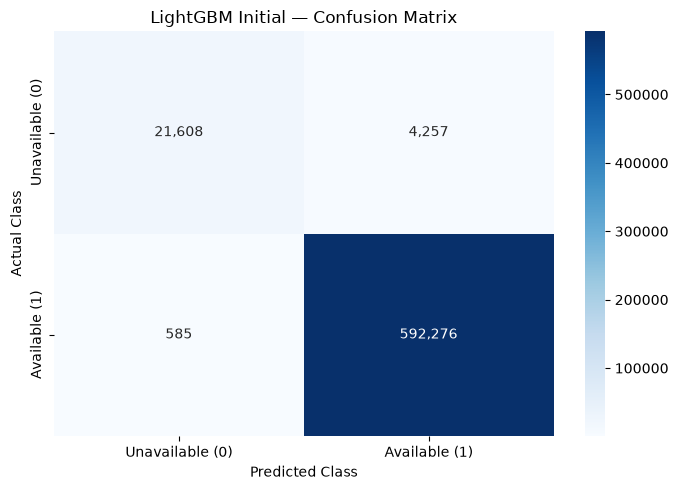

In [17]:
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss
)

from sklearn.calibration import calibration_curve

cm = confusion_matrix(
    y_validation,
    initial_labels,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Unavailable (0)", "Available (1)"],
    yticklabels=["Unavailable (0)", "Available (1)"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("LightGBM Initial — Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_initial_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

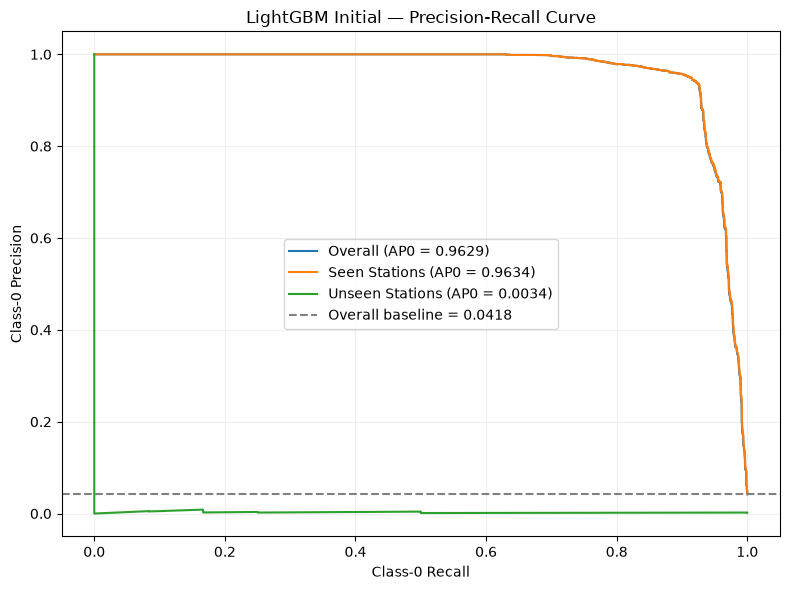

In [18]:
plt.figure(figsize=(8, 6))

evaluation_groups = {
    "Overall": np.ones(len(validation), dtype=bool),
    "Seen Stations": (~unseen_mask).to_numpy(),
    "Unseen Stations": unseen_mask.to_numpy()
}

for group_name, mask in evaluation_groups.items():

    y_unavailable = (
        y_validation.to_numpy()[mask] == 0
    ).astype(int)

    p_unavailable = 1 - initial_probabilities[mask]

    if len(np.unique(y_unavailable)) < 2:
        print(f"{group_name}: AP0 is N/A (single class)")
        continue

    precision, recall, _ = precision_recall_curve(
        y_unavailable,
        p_unavailable
    )

    ap0 = average_precision_score(
        y_unavailable,
        p_unavailable
    )

    plt.plot(
        recall,
        precision,
        label=f"{group_name} (AP0 = {ap0:.4f})"
    )

baseline = (y_validation == 0).mean()

plt.axhline(
    baseline,
    linestyle="--",
    color="gray",
    label=f"Overall baseline = {baseline:.4f}"
)

plt.xlabel("Class-0 Recall")
plt.ylabel("Class-0 Precision")
plt.title("LightGBM Initial — Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_initial_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

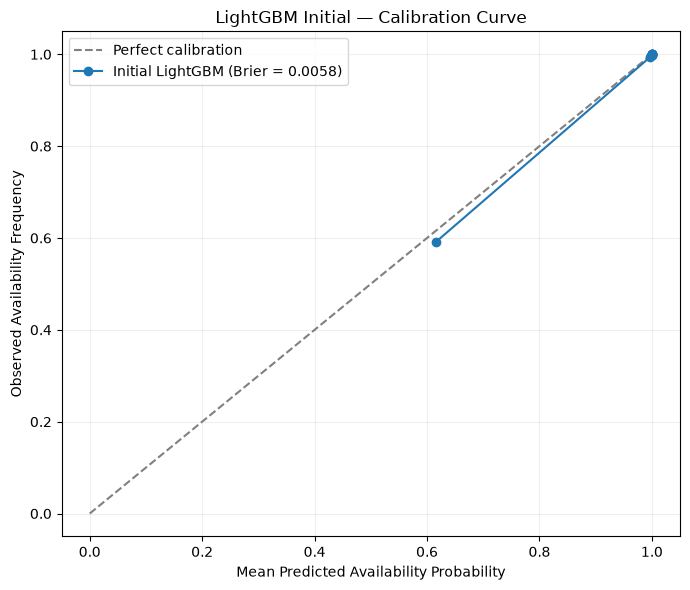

In [19]:
fraction_positive, mean_predicted = calibration_curve(
    y_validation,
    initial_probabilities,
    n_bins=10,
    strategy="quantile"
)

initial_brier = brier_score_loss(
    y_validation,
    initial_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label=f"Initial LightGBM (Brier = {initial_brier:.4f})"
)

plt.xlabel("Mean Predicted Availability Probability")
plt.ylabel("Observed Availability Frequency")
plt.title("LightGBM Initial — Calibration Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_initial_calibration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,feature,gain,split,gain_percentage
0,occupancy_rate,5.726193e+06,314,85.237773
1,idle_lag_10,2.384785e+05,268,3.549894
2,station_id,2.216175e+05,1050,3.298907
3,hour,1.839194e+05,1581,2.737748
4,day_of_week,1.123622e+05,963,1.672577
5,idle_lag_5,6.406307e+04,209,0.953617
6,idle_lag_15,6.134973e+04,148,0.913227
7,current_idle,2.834997e+04,211,0.422006
8,idle_lag_120,1.932141e+04,355,0.287611
9,idle_lag_40,1.751238e+04,148,0.260682


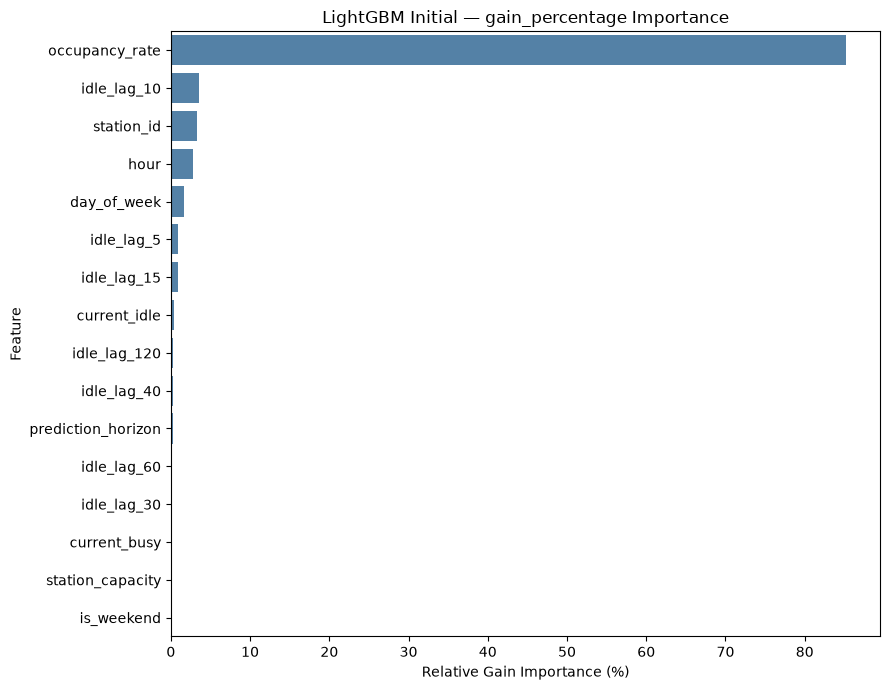

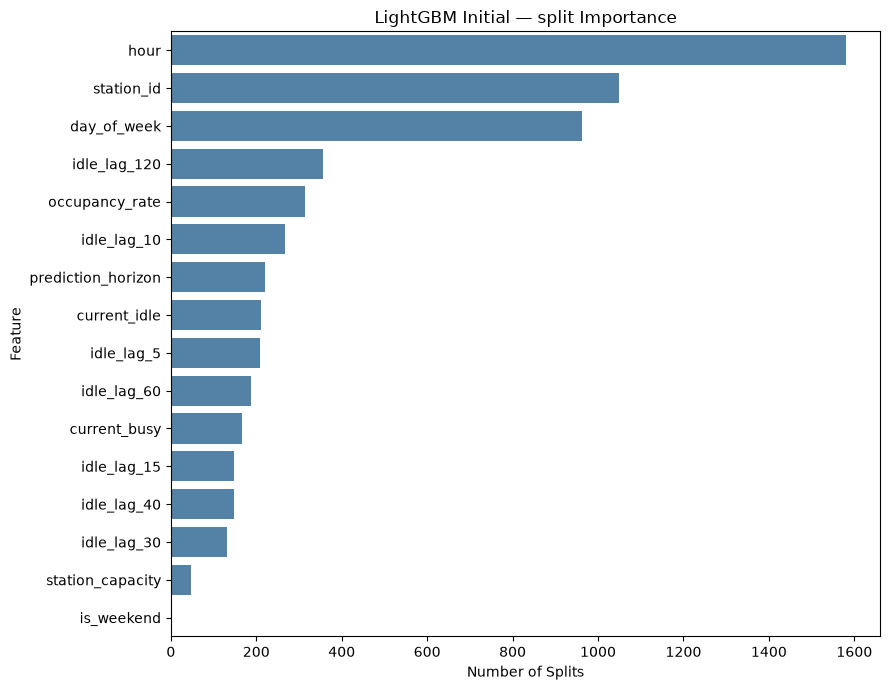

In [20]:
feature_importance = pd.DataFrame({
    "feature": initial_model.booster_.feature_name(),
    "gain": initial_model.booster_.feature_importance(
        importance_type="gain"
    ),
    "split": initial_model.booster_.feature_importance(
        importance_type="split"
    )
})

feature_importance["gain_percentage"] = (
    feature_importance["gain"]
    / feature_importance["gain"].sum()
    * 100
)

feature_importance = feature_importance.sort_values(
    "gain",
    ascending=False
).reset_index(drop=True)

feature_importance.to_csv(
    TABLE_DIR / "lightgbm_initial_feature_importance.csv",
    index=False
)

display(feature_importance)

for metric, xlabel in [
    ("gain_percentage", "Relative Gain Importance (%)"),
    ("split", "Number of Splits")
]:

    plot_data = feature_importance.sort_values(
        metric,
        ascending=False
    )

    plt.figure(figsize=(9, 7))

    sns.barplot(
        data=plot_data,
        x=metric,
        y="feature",
        color="steelblue"
    )

    plt.xlabel(xlabel)
    plt.ylabel("Feature")
    plt.title(f"LightGBM Initial — {metric} Importance")
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"lightgbm_initial_importance_{metric}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 9. Initial Model Error Analysis

Analyze incorrect predictions across prediction horizons,
station groups, station identifiers and hours of the day.

Particular attention is given to unavailable observations
incorrectly classified as available, as these errors may
lead users to fully occupied charging stations.

In [21]:
error_analysis = initial_predictions.copy()

error_analysis["hour"] = validation["hour"].to_numpy()

error_analysis["occupancy_rate"] = (
    validation["occupancy_rate"].to_numpy()
)

error_analysis["station_group"] = np.where(
    error_analysis["station_id"].isin(training_station_ids),
    "seen",
    "unseen"
)

error_analysis["error"] = (
    error_analysis["y_true"] != error_analysis["y_pred"]
)

error_analysis["missed_unavailable"] = (
    (error_analysis["y_true"] == 0)
    & (error_analysis["y_pred"] == 1)
)

error_analysis["false_alarm"] = (
    (error_analysis["y_true"] == 1)
    & (error_analysis["y_pred"] == 0)
)

error_analysis["actual_unavailable"] = (
    error_analysis["y_true"] == 0
)

assert error_analysis["error"].sum() == 4842
assert error_analysis["missed_unavailable"].sum() == 4257
assert error_analysis["false_alarm"].sum() == 585

print("Total errors:", error_analysis["error"].sum())

print(
    "Missed unavailable:",
    error_analysis["missed_unavailable"].sum()
)

print(
    "False alarms:",
    error_analysis["false_alarm"].sum()
)

Total errors: 4842
Missed unavailable: 4257
False alarms: 585


In [22]:
def summarize_errors(data, group_column):

    summary = data.groupby(group_column).agg(
        observations=("error", "size"),
        total_errors=("error", "sum"),
        actual_unavailable=("actual_unavailable", "sum"),
        missed_unavailable=("missed_unavailable", "sum"),
        false_alarms=("false_alarm", "sum")
    ).reset_index()

    summary["error_rate"] = (
        summary["total_errors"]
        / summary["observations"]
    )

    summary["missed_unavailable_rate"] = (
        summary["missed_unavailable"]
        / summary["actual_unavailable"].replace(0, np.nan)
    )

    return summary


error_tables = {}

for group_column in [
    "prediction_horizon",
    "station_group",
    "station_id",
    "hour"
]:

    summary = summarize_errors(
        error_analysis,
        group_column
    )

    error_tables[group_column] = summary

    summary.to_csv(
        TABLE_DIR / f"lightgbm_initial_errors_by_{group_column}.csv",
        index=False,
        na_rep="N/A"
    )

    print(f"Error analysis by {group_column}")

    if group_column == "station_id":
        display(
            summary.sort_values(
                "missed_unavailable",
                ascending=False
            ).head(10)
        )
    else:
        display(summary)

Error analysis by prediction_horizon


,prediction_horizon,observations,total_errors,actual_unavailable,missed_unavailable,false_alarms,error_rate,missed_unavailable_rate
0,30,206482,1513,8635,1338,175,0.007328,0.154951
1,40,206302,1596,8625,1405,191,0.007736,0.162899
2,60,205942,1733,8605,1514,219,0.008415,0.175944


Error analysis by station_group


,station_group,observations,total_errors,actual_unavailable,missed_unavailable,false_alarms,error_rate,missed_unavailable_rate
0,seen,612854,4830,25853,4245,585,0.007881,0.164198
1,unseen,5872,12,12,12,0,0.002044,1.000000


Error analysis by station_id


,station_id,observations,total_errors,actual_unavailable,missed_unavailable,false_alarms,error_rate,missed_unavailable_rate
8,1751,6886,2215,3031,2215,0,0.321667,0.730782
65,1879,6886,531,771,449,82,0.077113,0.582361
30,1796,6886,358,357,357,1,0.051990,1.000000
12,1763,6886,459,2352,264,195,0.066657,0.112245
69,1888,6886,410,774,238,172,0.059541,0.307494
31,1797,6886,201,201,201,0,0.029190,1.000000
34,1802,6886,108,108,108,0,0.015684,1.000000
71,1897,6886,123,102,102,21,0.017862,1.000000
19,1777,6886,60,54,52,8,0.008713,0.962963
10,1758,6886,109,3865,34,75,0.015829,0.008797


Error analysis by hour


,hour,observations,total_errors,actual_unavailable,missed_unavailable,false_alarms,error_rate,missed_unavailable_rate
0,0,25848,122,1058,122,0,0.004720,0.115312
1,1,25848,140,1076,140,0,0.005416,0.130112
2,2,25848,116,1046,108,8,0.004488,0.103250
3,3,25848,108,1044,108,0,0.004178,0.103448
4,4,25878,108,1044,108,0,0.004173,0.103448
5,5,25884,108,1044,108,0,0.004172,0.103448
6,6,25884,220,1030,205,15,0.008499,0.199029
7,7,25884,228,985,191,37,0.008809,0.193909
8,8,25884,214,1110,156,58,0.008268,0.140541
9,9,25884,291,1243,111,180,0.011242,0.089300


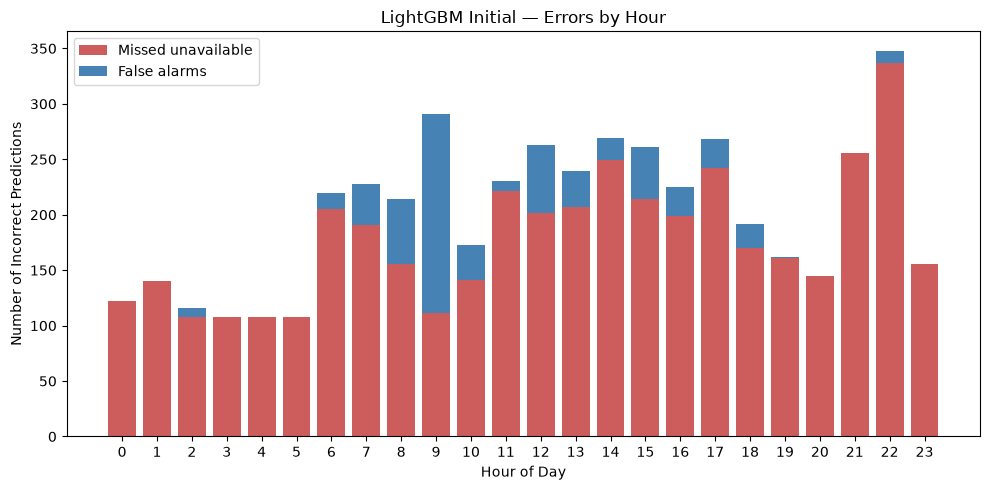

In [23]:
hourly_errors = error_tables["hour"]

plt.figure(figsize=(10, 5))

plt.bar(
    hourly_errors["hour"],
    hourly_errors["missed_unavailable"],
    label="Missed unavailable",
    color="indianred"
)

plt.bar(
    hourly_errors["hour"],
    hourly_errors["false_alarms"],
    bottom=hourly_errors["missed_unavailable"],
    label="False alarms",
    color="steelblue"
)

plt.xticks(range(24))
plt.xlabel("Hour of Day")
plt.ylabel("Number of Incorrect Predictions")
plt.title("LightGBM Initial — Errors by Hour")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_initial_errors_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

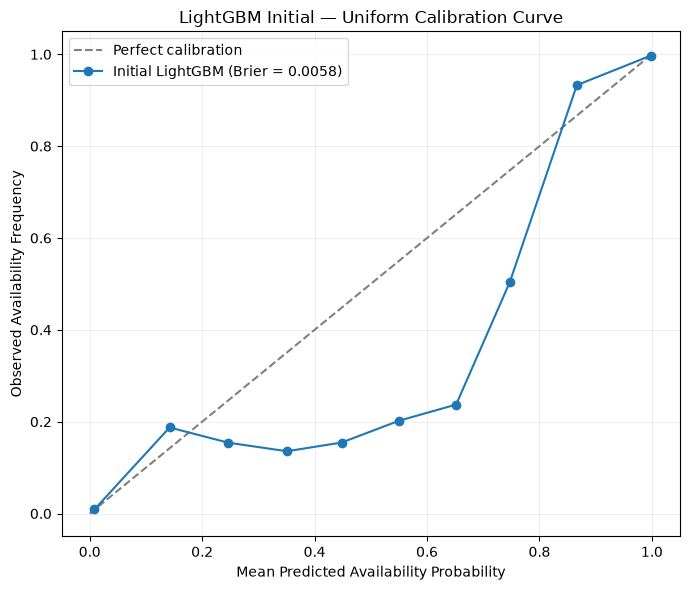

In [24]:
fraction_positive_uniform, mean_predicted_uniform = (
    calibration_curve(
        y_validation,
        initial_probabilities,
        n_bins=10,
        strategy="uniform"
    )
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted_uniform,
    fraction_positive_uniform,
    marker="o",
    label=f"Initial LightGBM (Brier = {initial_brier:.4f})"
)

plt.xlabel("Mean Predicted Availability Probability")
plt.ylabel("Observed Availability Frequency")
plt.title("LightGBM Initial — Uniform Calibration Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_initial_calibration_uniform.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Initial Model Findings

The initial LightGBM model achieved an overall accuracy of
99.22%, a Class-0 F1-score of 0.899247 and a seen-station
Class-0 Average Precision of 0.963382.

Performance decreased as the prediction horizon increased,
with the highest Average Precision observed at 30 minutes.

The model correctly identified 21,608 unavailable observations
but incorrectly classified 4,257 unavailable observations
as available.

Although unseen-station accuracy reached 99.80%, the model
failed to identify any of the 12 unavailable observations
at the unseen validation station. This highlights a limitation
in generalization to previously unseen stations.

Occupancy rate was the dominant feature by gain importance,
while hour was the most frequently used splitting feature.
The is_weekend feature had zero gain and split importance.

The model was trained on 1,790,062 observations in 20.342
seconds and generated 618,726 validation predictions in
3.498 seconds using four CPU threads.

Further optimization will investigate hyperparameter tuning,
class weighting, feature reduction, probability calibration
and classification threshold selection using only the
approved internal training periods.

### Error Analysis Findings

The initial model produced 4,842 incorrect predictions,
including 4,257 missed unavailable observations and
585 false alarms.

Station 1751 accounted for 52.03% of all missed unavailable
observations, indicating that errors were concentrated
in particular stations.

The highest hourly error count occurred at 22:00, with
348 incorrect predictions.

The uniform calibration curve indicated that availability
probabilities were overestimated in several intermediate
probability bins.

These findings highlight limitations in station-level
generalization and probability calibration.

## 11. LightGBM Hyperparameter Optimization

Hyperparameter candidates are trained exclusively on the
Model Fit period and evaluated on the Tuning period.

Early stopping is based on Class-0 Average Precision.

The optimization investigates:

- Tree complexity
- Learning rate and number of estimators
- Minimum child samples
- Feature and row subsampling
- L1 and L2 regularization
- Minority-class weighting
- Reduced feature configurations

The official validation and test datasets are not used
for hyperparameter selection.

In [25]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    brier_score_loss
)

X_tuning = prepare_features(
    tuning,
    FEATURE_COLUMNS,
    station_categories
)

y_tuning = tuning["target"].astype("int8")

assert X_tuning.shape == (466897, 16)
assert len(y_tuning) == len(X_tuning)

class_counts = y_fit.value_counts()

minority_weight = float(
    class_counts[1] / class_counts[0]
)

print("Model Fit observations:", len(X_fit))
print("Tuning observations:", len(X_tuning))
print("Minority class weight:", round(minority_weight, 4))

display(y_tuning.value_counts().sort_index())

Model Fit observations: 1790062
Tuning observations: 466897
Minority class weight: 19.3536


target
0     20726
1    446171
Name: count, dtype: int64

In [26]:
def class0_ap_metric(y_true, y_prob):
    """LightGBM evaluation metric for unavailable observations."""

    y_unavailable = (
        np.asarray(y_true) == 0
    ).astype(int)

    p_unavailable = 1 - np.asarray(y_prob)

    score = average_precision_score(
        y_unavailable,
        p_unavailable
    )

    return "ap_0", float(score), True


initial_tuning_probabilities = predict_availability(
    initial_model,
    X_tuning
)

initial_tuning_ap0 = average_precision_score(
    (y_tuning == 0).astype(int),
    1 - initial_tuning_probabilities
)

print(
    "Initial model tuning AP0:",
    round(initial_tuning_ap0, 6)
)

Initial model tuning AP0: 0.97952


In [27]:
base_params = initial_model.get_params().copy()

base_params.update({
    "n_estimators": 600,
    "metric": "None"
})

candidates = {
    "baseline_extended": {},

    "smaller_trees": {
        "num_leaves": 15,
        "max_depth": 4
    },

    "larger_trees": {
        "num_leaves": 63,
        "max_depth": 8
    },

    "slower_learning": {
        "learning_rate": 0.025,
        "n_estimators": 1000
    },

    "larger_min_child": {
        "min_child_samples": 150
    },

    "feature_subsampling": {
        "colsample_bytree": 0.8
    },

    "row_subsampling": {
        "subsample": 0.8,
        "subsample_freq": 1
    },

    "regularized": {
        "reg_alpha": 0.5,
        "reg_lambda": 2.0
    },

    "moderate_class_weight": {
        "class_weight": {
            0: 5.0,
            1: 1.0
        }
    },

    "balanced_class_weight": {
        "class_weight": {
            0: minority_weight,
            1: 1.0
        }
    }
}

candidate_table = pd.DataFrame([
    {"candidate": name, **overrides}
    for name, overrides in candidates.items()
])

print("Number of candidates:", len(candidates))

display(candidate_table)

Number of candidates: 10


,candidate,num_leaves,max_depth,learning_rate,n_estimators,min_child_samples,colsample_bytree,subsample,subsample_freq,reg_alpha,reg_lambda,class_weight
0,baseline_extended,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,smaller_trees,15.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,larger_trees,63.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,slower_learning,NaN,NaN,0.025,1000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,larger_min_child,NaN,NaN,NaN,NaN,150.0,NaN,NaN,NaN,NaN,NaN,NaN
5,feature_subsampling,NaN,NaN,NaN,NaN,NaN,0.8,NaN,NaN,NaN,NaN,NaN
6,row_subsampling,NaN,NaN,NaN,NaN,NaN,NaN,0.8,1.0,NaN,NaN,NaN
7,regularized,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,2.0,NaN
8,moderate_class_weight,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{0: 5.0, 1: 1.0}"
9,balanced_class_weight,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{0: 19.353640787738208, 1: 1.0}"


In [28]:
def evaluate_candidate(
    candidate_name,
    overrides,
    features
):
    params = base_params.copy()
    params.update(overrides)

    model = LGBMClassifier(**params)

    categorical_features = [
        feature for feature in features
        if feature == "station_id"
    ]

    start = time.perf_counter()

    model.fit(
        X_fit[features],
        y_fit,
        categorical_feature=categorical_features,
        eval_set=[
            (X_tuning[features], y_tuning)
        ],
        eval_metric=class0_ap_metric,
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=40,
                first_metric_only=True,
                verbose=False
            ),
            lgb.log_evaluation(period=0)
        ]
    )

    training_seconds = time.perf_counter() - start

    start = time.perf_counter()

    probabilities = predict_availability(
        model,
        X_tuning[features]
    )

    inference_seconds = time.perf_counter() - start

    labels = predict_labels(probabilities, 0.5)

    result = {
        "candidate": candidate_name,
        "feature_count": len(features),
        "best_iteration": int(model.best_iteration_),
        "ap_0": average_precision_score(
            (y_tuning == 0).astype(int),
            1 - probabilities
        ),
        "f1_0": f1_score(
            y_tuning, labels,
            pos_label=0,
            zero_division=0
        ),
        "precision_0": precision_score(
            y_tuning, labels,
            pos_label=0,
            zero_division=0
        ),
        "recall_0": recall_score(
            y_tuning, labels,
            pos_label=0,
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_tuning, labels
        ),
        "roc_auc": roc_auc_score(
            y_tuning, probabilities
        ),
        "brier_score": brier_score_loss(
            y_tuning, probabilities
        ),
        "training_seconds": training_seconds,
        "inference_seconds": inference_seconds
    }

    return result

In [29]:
tuning_results = []

for index, (name, overrides) in enumerate(
    candidates.items(), start=1
):
    print(
        f"[{index}/{len(candidates)}] Training {name}...",
        flush=True
    )

    result = evaluate_candidate(
        name,
        overrides,
        FEATURE_COLUMNS
    )

    tuning_results.append(result)

    print(
        f"AP0: {result['ap_0']:.6f} | "
        f"F1: {result['f1_0']:.6f} | "
        f"Best iteration: {result['best_iteration']} | "
        f"Time: {result['training_seconds']:.2f}s",
        flush=True
    )

tuning_results_df = pd.DataFrame(
    tuning_results
).sort_values(
    "ap_0",
    ascending=False
).reset_index(drop=True)

tuning_results_df.to_csv(
    TABLE_DIR / "lightgbm_hyperparameter_results.csv",
    index=False
)

display(tuning_results_df)

[1/10] Training baseline_extended...


c:\Users\Ahmet\VoltAhead\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AP0: 0.983739 | F1: 0.958087 | Best iteration: 17 | Time: 10.61s
[2/10] Training smaller_trees...


c:\Users\Ahmet\VoltAhead\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AP0: 0.983988 | F1: 0.964236 | Best iteration: 39 | Time: 11.83s
[3/10] Training larger_trees...


c:\Users\Ahmet\VoltAhead\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (12 outputs left out)

AP0: 0.982335 | F1: 0.971221 | Best iteration: 52 | Time: 15.07s
[10/10] Training balanced_class_weight...


c:\Users\Ahmet\VoltAhead\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AP0: 0.979721 | F1: 0.950384 | Best iteration: 51 | Time: 15.16s


,candidate,feature_count,best_iteration,ap_0,f1_0,precision_0,recall_0,balanced_accuracy,roc_auc,brier_score,training_seconds,inference_seconds
0,feature_subsampling,16,77,0.984305,0.973197,0.983066,0.963524,0.981377,0.995319,0.002082,18.688754,0.729304
1,larger_min_child,16,65,0.984079,0.972236,0.984229,0.960533,0.979909,0.995603,0.002103,16.988680,0.493348
2,smaller_trees,16,39,0.983988,0.964236,0.984222,0.945045,0.972171,0.994807,0.002994,11.826836,0.258860
3,regularized,16,62,0.983933,0.971963,0.983263,0.960919,0.980079,0.995389,0.002233,16.557933,0.468107
4,row_subsampling,16,60,0.983924,0.971589,0.981441,0.961932,0.980543,0.995508,0.002245,17.046305,0.458351
5,baseline_extended,16,17,0.983739,0.958087,0.991332,0.927000,0.963312,0.993831,0.008641,10.607416,0.177019
6,slower_learning,16,33,0.983589,0.958608,0.993223,0.926324,0.963015,0.993822,0.009588,11.343445,0.274132
7,larger_trees,16,8,0.982827,0.000000,0.000000,0.000000,0.500000,0.993296,0.018247,8.238761,0.166592
8,moderate_class_weight,16,52,0.982335,0.971221,0.974452,0.968011,0.983416,0.995025,0.003026,15.068740,0.406630
9,balanced_class_weight,16,51,0.979721,0.950384,0.930755,0.970858,0.983751,0.994056,0.006937,15.164574,0.418878


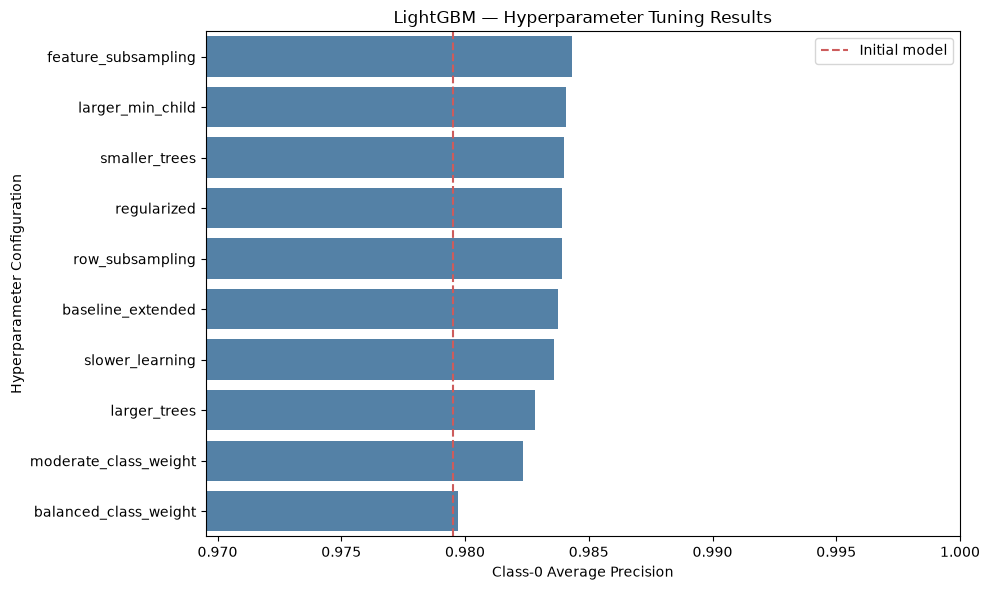

Best candidate: feature_subsampling


,candidate,feature_count,best_iteration,ap_0,f1_0,precision_0,recall_0,balanced_accuracy,roc_auc,brier_score,training_seconds,inference_seconds
0,feature_subsampling,16,77,0.984305,0.973197,0.983066,0.963524,0.981377,0.995319,0.002082,18.688754,0.729304
1,larger_min_child,16,65,0.984079,0.972236,0.984229,0.960533,0.979909,0.995603,0.002103,16.988680,0.493348
2,smaller_trees,16,39,0.983988,0.964236,0.984222,0.945045,0.972171,0.994807,0.002994,11.826836,0.258860


In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=tuning_results_df,
    x="ap_0",
    y="candidate",
    color="steelblue"
)

plt.axvline(
    initial_tuning_ap0,
    linestyle="--",
    color="indianred",
    label="Initial model"
)

plt.xlim(
    max(
        0,
        min(
            tuning_results_df["ap_0"].min(),
            initial_tuning_ap0
        ) - 0.01
    ),
    1.0
)

plt.xlabel("Class-0 Average Precision")
plt.ylabel("Hyperparameter Configuration")
plt.title("LightGBM — Hyperparameter Tuning Results")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_hyperparameter_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

best_candidate_name = tuning_results_df.iloc[0]["candidate"]

print("Best candidate:", best_candidate_name)

display(tuning_results_df.head(3))

### Hyperparameter Optimization Findings

Ten hyperparameter configurations were evaluated using
the chronological Tuning period.

Feature subsampling achieved the highest Class-0 Average
Precision (0.984305), compared with 0.979520 for the
initial model on the same Tuning period.

The selected configuration achieved a Class-0 F1 score
of 0.973197 with only 77 boosting iterations.

Class weighting improved minority-class recall but did
not produce the highest Average Precision.

These results demonstrate that improved predictive
performance can be achieved with fewer boosting iterations.

## 12. Reduced Feature Comparison

Reduced feature configurations are investigated to assess
the trade-off between predictive performance, computational
efficiency and model complexity.

Feature subsets are motivated by feature importance,
feature redundancy and station-level generalization.

All configurations are trained on the Model Fit period
and evaluated exclusively on the Tuning period.

The official validation and test datasets are not used
for feature-set selection.

In [31]:
feature_sets = {
    "full_16": list(FEATURE_COLUMNS),

    "reduced_12": [
        feature for feature in FEATURE_COLUMNS
        if feature not in [
            "is_weekend",
            "current_busy",
            "idle_lag_30",
            "idle_lag_60"
        ]
    ],

    "compact_8": [
        "station_id",
        "hour",
        "day_of_week",
        "occupancy_rate",
        "idle_lag_5",
        "idle_lag_10",
        "idle_lag_15",
        "prediction_horizon"
    ],

    "without_station_id_15": [
        feature for feature in FEATURE_COLUMNS
        if feature != "station_id"
    ]
}

for name, features in feature_sets.items():
    assert set(features).issubset(FEATURE_COLUMNS)
    assert "prediction_horizon" in features

    print(f"{name}: {len(features)} features")
    print(features)
    print()

full_16: 16 features
['station_id', 'hour', 'day_of_week', 'is_weekend', 'current_idle', 'current_busy', 'station_capacity', 'occupancy_rate', 'idle_lag_5', 'idle_lag_10', 'idle_lag_15', 'idle_lag_30', 'idle_lag_40', 'idle_lag_60', 'idle_lag_120', 'prediction_horizon']

reduced_12: 12 features
['station_id', 'hour', 'day_of_week', 'current_idle', 'station_capacity', 'occupancy_rate', 'idle_lag_5', 'idle_lag_10', 'idle_lag_15', 'idle_lag_40', 'idle_lag_120', 'prediction_horizon']

compact_8: 8 features
['station_id', 'hour', 'day_of_week', 'occupancy_rate', 'idle_lag_5', 'idle_lag_10', 'idle_lag_15', 'prediction_horizon']

without_station_id_15: 15 features
['hour', 'day_of_week', 'is_weekend', 'current_idle', 'current_busy', 'station_capacity', 'occupancy_rate', 'idle_lag_5', 'idle_lag_10', 'idle_lag_15', 'idle_lag_30', 'idle_lag_40', 'idle_lag_60', 'idle_lag_120', 'prediction_horizon']



In [32]:
best_overrides = candidates[best_candidate_name].copy()

feature_results = []

# Reuse the existing full-feature result
full_result = tuning_results_df.loc[
    tuning_results_df["candidate"] == best_candidate_name
].iloc[0].to_dict()

full_result["feature_set"] = "full_16"

feature_results.append(full_result)

# Evaluate alternative feature sets
for name, features in feature_sets.items():

    if name == "full_16":
        continue

    print(f"Training {name}...", flush=True)

    result = evaluate_candidate(
        name,
        best_overrides,
        features
    )

    result["feature_set"] = name

    feature_results.append(result)

    print(
        f"AP0: {result['ap_0']:.6f} | "
        f"F1: {result['f1_0']:.6f} | "
        f"Trees: {result['best_iteration']} | "
        f"Time: {result['training_seconds']:.2f}s",
        flush=True
    )

feature_results_df = pd.DataFrame(
    feature_results
).sort_values(
    "ap_0",
    ascending=False
).reset_index(drop=True)

feature_results_df.to_csv(
    TABLE_DIR / "lightgbm_feature_comparison.csv",
    index=False
)

display(feature_results_df)

Training reduced_12...


c:\Users\Ahmet\VoltAhead\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AP0: 0.984422 | F1: 0.955168 | Trees: 13 | Time: 11.43s
Training compact_8...


c:\Users\Ahmet\VoltAhead\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AP0: 0.983840 | F1: 0.000000 | Trees: 6 | Time: 9.02s
Training without_station_id_15...


c:\Users\Ahmet\VoltAhead\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AP0: 0.982296 | F1: 0.974197 | Trees: 51 | Time: 19.91s


,candidate,feature_count,best_iteration,ap_0,f1_0,precision_0,recall_0,balanced_accuracy,roc_auc,brier_score,training_seconds,inference_seconds,feature_set
0,reduced_12,12,13,0.984422,0.955168,0.997322,0.916433,0.958160,0.994685,0.011795,11.426948,0.200397,reduced_12
1,feature_subsampling,16,77,0.984305,0.973197,0.983066,0.963524,0.981377,0.995319,0.002082,18.688754,0.729304,full_16
2,compact_8,8,6,0.983840,0.000000,0.000000,0.000000,0.500000,0.994526,0.022004,9.022701,0.132536,compact_8
3,without_station_id_15,15,51,0.982296,0.974197,0.973821,0.974573,0.986678,0.995321,0.002115,19.912227,0.510104,without_station_id_15


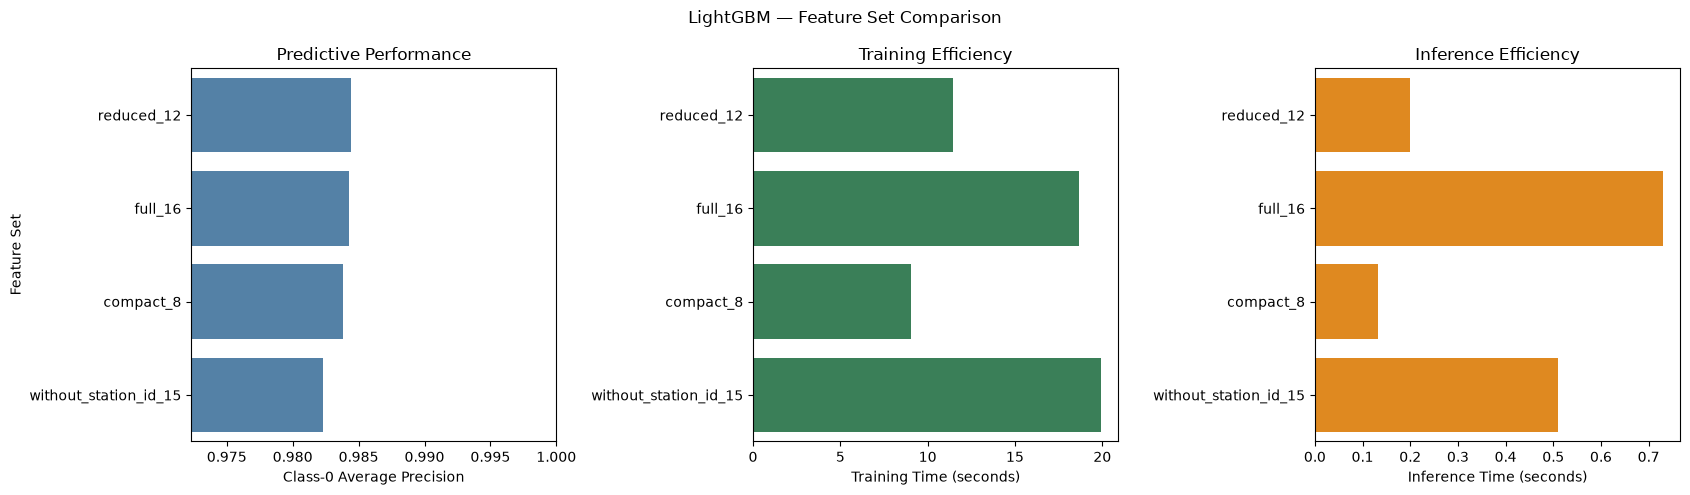

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=feature_results_df,
    x="ap_0",
    y="feature_set",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Predictive Performance")
axes[0].set_xlabel("Class-0 Average Precision")
axes[0].set_ylabel("Feature Set")
axes[0].set_xlim(
    max(0, feature_results_df["ap_0"].min() - 0.01),
    1.0
)

sns.barplot(
    data=feature_results_df,
    x="training_seconds",
    y="feature_set",
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Training Efficiency")
axes[1].set_xlabel("Training Time (seconds)")
axes[1].set_ylabel("")

sns.barplot(
    data=feature_results_df,
    x="inference_seconds",
    y="feature_set",
    ax=axes[2],
    color="darkorange"
)

axes[2].set_title("Inference Efficiency")
axes[2].set_xlabel("Inference Time (seconds)")
axes[2].set_ylabel("")

plt.suptitle("LightGBM — Feature Set Comparison")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
selected_result = feature_results_df.iloc[0]

selected_feature_set = selected_result["feature_set"]

selected_features = feature_sets[selected_feature_set]

selected_iterations = int(
    selected_result["best_iteration"]
)

optimized_params = base_params.copy()

optimized_params.update(best_overrides)

optimized_params["n_estimators"] = selected_iterations

print("Selected hyperparameter candidate:", best_candidate_name)
print("Selected feature set:", selected_feature_set)
print("Number of features:", len(selected_features))
print("Number of trees:", selected_iterations)
print("Tuning AP0:", selected_result["ap_0"])
print("Tuning F1:", selected_result["f1_0"])

display(pd.Series(optimized_params))

Selected hyperparameter candidate: feature_subsampling
Selected feature set: reduced_12
Number of features: 12
Number of trees: 13
Tuning AP0: 0.9844218662741901
Tuning F1: 0.9551683387392824


boosting_type          gbdt
class_weight           None
colsample_bytree        0.8
importance_type       split
learning_rate          0.05
max_depth                 6
min_child_samples        50
min_child_weight      0.001
min_split_gain          0.0
n_estimators             13
n_jobs                    4
num_leaves               31
objective            binary
random_state             42
reg_alpha               0.0
reg_lambda              0.0
subsample               1.0
subsample_for_bin    200000
subsample_freq            0
device_type             cpu
deterministic          True
force_col_wise         True
verbosity                -1
metric                 None
dtype: object

### Feature Selection Findings

The reduced 12-feature configuration achieved the
highest Class-0 Average Precision of 0.984422.

Compared with the full-feature tuned configuration,
it reduced the number of features by 25% and the
number of boosting iterations from 77 to 13.

Training and inference times were also reduced.

However, the reduced configuration achieved a lower
Class-0 F1 score at the default threshold and a higher
Brier score.

The reduced configuration was selected based on the
primary tuning metric, Class-0 Average Precision.

Probability calibration and threshold optimization
will be investigated in subsequent stages.

## 13. Optimized Model Training

The selected LightGBM configuration is refitted using
the combined Model Fit and Tuning periods
(December 1–29, 2022).

The selected feature subset, hyperparameters and number
of boosting iterations are fixed before refitting.

Calibration, Threshold, Validation and Test observations
are excluded from model fitting.

In [35]:
optimized_station_categories = fit_station_categories(
    fit_tuning
)

X_optimized_fit = prepare_features(
    fit_tuning,
    selected_features,
    optimized_station_categories
)

y_optimized_fit = fit_tuning["target"].astype("int8")

assert len(X_optimized_fit) == 2259325
assert len(y_optimized_fit) == 2259325

assert X_optimized_fit.shape[1] == len(selected_features)

assert len(optimized_station_categories) == 91

assert X_optimized_fit["station_id"].notna().all()

optimized_fit_memory_mb = (
    X_optimized_fit.memory_usage(deep=True).sum()
    + y_optimized_fit.memory_usage(deep=True)
) / (1024 ** 2)

print("Optimized training features:", X_optimized_fit.shape)
print("Optimized training target:", y_optimized_fit.shape)
print("Station categories:", len(optimized_station_categories))
print("Input memory (MiB):", round(optimized_fit_memory_mb, 2))

display(y_optimized_fit.value_counts().sort_index())

Optimized training features: (2259325, 12)
Optimized training target: (2259325,)
Station categories: 91
Input memory (MiB): 159.45


target
0     108804
1    2150521
Name: count, dtype: int64

In [36]:
optimized_model = LGBMClassifier(
    **optimized_params
)

start_time = time.perf_counter()

optimized_model.fit(
    X_optimized_fit,
    y_optimized_fit,
    categorical_feature=["station_id"]
)

optimized_training_time = (
    time.perf_counter() - start_time
)

assert optimized_model.n_features_in_ == len(
    selected_features
)

assert list(optimized_model.classes_) == [0, 1]

assert optimized_model.feature_name_ == selected_features

assert optimized_model.booster_.num_trees() == selected_iterations

print("Optimized model training: PASSED")

print("Training observations:", len(X_optimized_fit))

print(
    "Training time (seconds):",
    round(optimized_training_time, 3)
)

print("Number of features:", optimized_model.n_features_in_)

print("Number of trees:", optimized_model.booster_.num_trees())

print("Model classes:", optimized_model.classes_)

Optimized model training: PASSED
Training observations: 2259325
Training time (seconds): 2.233
Number of features: 12
Number of trees: 13
Model classes: [0 1]


## 14. Probability Calibration

Three probability calibration approaches are compared:

- Uncalibrated probabilities
- Platt scaling
- Isotonic regression

The Calibration period is divided chronologically
into calibration fitting and calibration assessment
subsets.

The calibration method is selected using the Brier
score on the assessment subset.

The selected calibration method is then refitted
using the complete Calibration period.

The Threshold, Validation and Test periods remain
excluded from calibration fitting and selection.

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

X_calibration = prepare_features(
    calibration,
    selected_features,
    optimized_station_categories
)

y_calibration = calibration["target"].astype("int8")

assert len(X_calibration) == 306216

calibration_raw_probabilities = predict_availability(
    optimized_model,
    X_calibration
)

assert np.isfinite(calibration_raw_probabilities).all()

assert np.all(
    (calibration_raw_probabilities >= 0)
    & (calibration_raw_probabilities <= 1)
)

calibration_boundary = pd.Timestamp("2023-01-01")

calibration_fit_mask = (
    (calibration["time"] < calibration_boundary)
    & (calibration["target_time"] < calibration_boundary)
).to_numpy()

calibration_assessment_mask = (
    (calibration["time"] >= calibration_boundary)
    & (calibration["target_time"] >= calibration_boundary)
).to_numpy()

assert not np.any(
    calibration_fit_mask & calibration_assessment_mask
)

print("Calibration observations:", len(X_calibration))

print(
    "Calibration fitting observations:",
    calibration_fit_mask.sum()
)

print(
    "Calibration assessment observations:",
    calibration_assessment_mask.sum()
)

print(
    "Boundary-crossing observations excluded from selection:",
    len(calibration)
    - calibration_fit_mask.sum()
    - calibration_assessment_mask.sum()
)

print(
    "Raw probability range:",
    calibration_raw_probabilities.min(),
    calibration_raw_probabilities.max()
)

Calibration observations: 306216
Calibration fitting observations: 152424
Calibration assessment observations: 151478
Boundary-crossing observations excluded from selection: 2314
Raw probability range: 0.4639794513889853 0.9744932799827202


In [38]:
def probability_to_logit(probabilities):
    probabilities = np.clip(
        np.asarray(probabilities),
        1e-12,
        1 - 1e-12
    )

    return np.log(
        probabilities / (1 - probabilities)
    ).reshape(-1, 1)


p_cal_fit = calibration_raw_probabilities[
    calibration_fit_mask
]

y_cal_fit = y_calibration.to_numpy()[
    calibration_fit_mask
]

p_cal_assessment = calibration_raw_probabilities[
    calibration_assessment_mask
]

y_cal_assessment = y_calibration.to_numpy()[
    calibration_assessment_mask
]

assert len(np.unique(y_cal_fit)) == 2
assert len(np.unique(y_cal_assessment)) == 2

platt_calibrator = LogisticRegression(
    C=1.0,
    random_state=SEED,
    max_iter=1000
)

platt_calibrator.fit(
    probability_to_logit(p_cal_fit),
    y_cal_fit
)

isotonic_calibrator = IsotonicRegression(
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    p_cal_fit,
    y_cal_fit
)

calibration_candidates = {
    "uncalibrated": p_cal_assessment,

    "platt": platt_calibrator.predict_proba(
        probability_to_logit(p_cal_assessment)
    )[:, 1],

    "isotonic": isotonic_calibrator.predict(
        p_cal_assessment
    )
}

print("Calibration candidates fitted successfully.")

Calibration candidates fitted successfully.


In [39]:
calibration_results = []

for method, probabilities in calibration_candidates.items():

    assert np.isfinite(probabilities).all()

    assert np.all(
        (probabilities >= 0)
        & (probabilities <= 1)
    )

    labels = predict_labels(probabilities, 0.5)

    calibration_results.append({
        "method": method,

        "brier_score": brier_score_loss(
            y_cal_assessment,
            probabilities
        ),

        "ap_0": average_precision_score(
            (y_cal_assessment == 0).astype(int),
            1 - probabilities
        ),

        "roc_auc": roc_auc_score(
            y_cal_assessment,
            probabilities
        ),

        "f1_0": f1_score(
            y_cal_assessment,
            labels,
            pos_label=0,
            zero_division=0
        )
    })

calibration_results_df = pd.DataFrame(
    calibration_results
).sort_values(
    "brier_score",
    ascending=True
).reset_index(drop=True)

calibration_results_df.to_csv(
    TABLE_DIR / "lightgbm_calibration_comparison.csv",
    index=False
)

selected_calibration_method = (
    calibration_results_df.iloc[0]["method"]
)

display(calibration_results_df)

print(
    "Selected calibration method:",
    selected_calibration_method
)

,method,brier_score,ap_0,roc_auc,f1_0
0,platt,0.003660,0.982832,0.998025,0.927934
1,isotonic,0.005261,0.974010,0.991618,0.874151
2,uncalibrated,0.011341,0.982832,0.998025,0.864958


Selected calibration method: platt


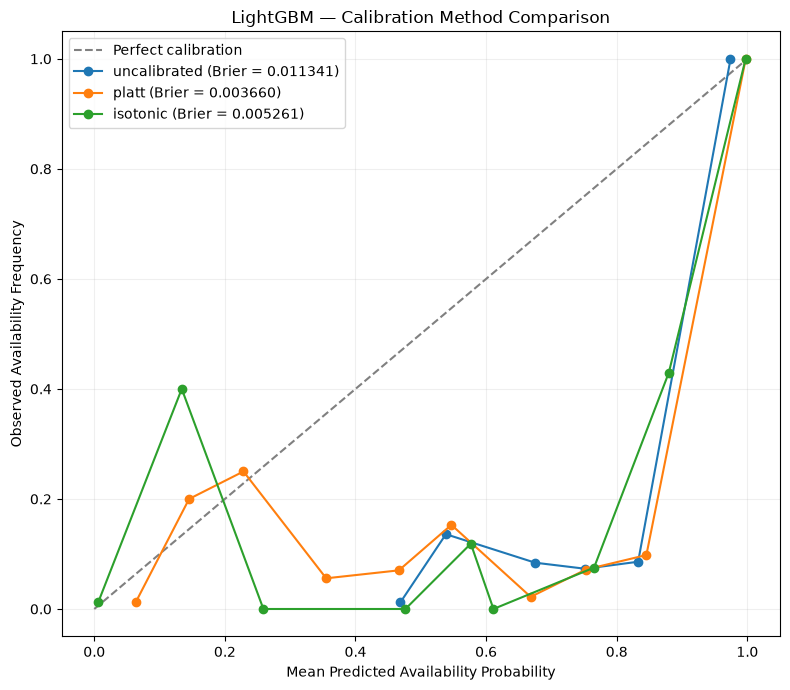

In [40]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

for method, probabilities in calibration_candidates.items():

    observed, predicted = calibration_curve(
        y_cal_assessment,
        probabilities,
        n_bins=10,
        strategy="uniform"
    )

    score = brier_score_loss(
        y_cal_assessment,
        probabilities
    )

    plt.plot(
        predicted,
        observed,
        marker="o",
        label=f"{method} (Brier = {score:.6f})"
    )

plt.xlabel("Mean Predicted Availability Probability")
plt.ylabel("Observed Availability Frequency")
plt.title("LightGBM — Calibration Method Comparison")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_calibration_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Calibration Method Selection

Platt scaling achieved the lowest Brier score
of 0.003660 on the calibration assessment subset.

Compared with uncalibrated probabilities, Platt
scaling reduced the Brier score by approximately
67.7% while preserving Class-0 Average Precision.

Therefore, Platt scaling was selected and refitted
using the complete Calibration period.

The optimized LightGBM estimator remains unchanged.

In [41]:
final_calibrator = LogisticRegression(
    C=1.0,
    random_state=SEED,
    max_iter=1000
)

start_time = time.perf_counter()

final_calibrator.fit(
    probability_to_logit(
        calibration_raw_probabilities
    ),
    y_calibration
)

calibration_training_time = (
    time.perf_counter() - start_time
)

assert list(final_calibrator.classes_) == [0, 1]
assert final_calibrator.coef_[0, 0] > 0

print("Final Platt calibrator: PASSED")
print("Calibration observations:", len(y_calibration))

print(
    "Calibration training time (seconds):",
    round(calibration_training_time, 3)
)

print("Coefficient:", final_calibrator.coef_[0, 0])
print("Intercept:", final_calibrator.intercept_[0])

Final Platt calibrator: PASSED
Calibration observations: 306216
Calibration training time (seconds): 0.271
Coefficient: 2.599611325950278
Intercept: -3.278450588052936


In [42]:
def predict_calibrated_availability(
    model,
    features,
    calibrator
):
    """Return calibrated P(Available = 1)."""

    raw_probabilities = predict_availability(
        model,
        features
    )

    calibrated_probabilities = (
        calibrator.predict_proba(
            probability_to_logit(raw_probabilities)
        )[:, 1]
    )

    assert np.isfinite(calibrated_probabilities).all()

    assert np.all(
        (calibrated_probabilities >= 0)
        & (calibrated_probabilities <= 1)
    )

    return calibrated_probabilities


print("Calibrated prediction function ready.")

Calibrated prediction function ready.


## 15. Threshold Optimization

The classification threshold is optimized using
the dedicated Threshold period (January 3–5, 2023).

The objective is to maximize the F1 score for
Class 0 (Unavailable).

Predicted probabilities represent P(Available = 1).

An observation is classified as Available when
its probability is greater than or equal to
the selected threshold.

The LightGBM estimator and Platt calibrator
remain fixed throughout threshold optimization.

Validation and Test observations are not used
for threshold selection.

In [43]:
X_threshold = prepare_features(
    threshold_data,
    selected_features,
    optimized_station_categories
)

y_threshold = threshold_data["target"].astype("int8")

assert len(X_threshold) == 228374
assert len(y_threshold) == 228374

threshold_probabilities = (
    predict_calibrated_availability(
        optimized_model,
        X_threshold,
        final_calibrator
    )
)

print("Threshold features:", X_threshold.shape)
print("Threshold target:", y_threshold.shape)

print(
    "Minimum probability:",
    threshold_probabilities.min()
)

print(
    "Maximum probability:",
    threshold_probabilities.max()
)

display(y_threshold.value_counts().sort_index())

Threshold features: (228374, 12)
Threshold target: (228374,)
Minimum probability: 0.024658972539494957
Maximum probability: 0.9979581808834522


target
0      8610
1    219764
Name: count, dtype: int64

In [44]:
threshold_grid = np.round(
    np.arange(0.01, 1.00, 0.01),
    2
)

threshold_results = []

for threshold in threshold_grid:

    labels = predict_labels(
        threshold_probabilities,
        threshold
    )

    threshold_results.append({
        "threshold": float(threshold),

        "precision_0": precision_score(
            y_threshold,
            labels,
            pos_label=0,
            zero_division=0
        ),

        "recall_0": recall_score(
            y_threshold,
            labels,
            pos_label=0,
            zero_division=0
        ),

        "f1_0": f1_score(
            y_threshold,
            labels,
            pos_label=0,
            zero_division=0
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_threshold,
            labels
        ),

        "predicted_unavailable": int(
            (labels == 0).sum()
        )
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

threshold_results_df.to_csv(
    TABLE_DIR / "lightgbm_threshold_search.csv",
    index=False
)

display(
    threshold_results_df.sort_values(
        "f1_0",
        ascending=False
    ).head(10)
)

,threshold,precision_0,recall_0,f1_0,balanced_accuracy,predicted_unavailable
81,0.82,0.932592,0.915912,0.924177,0.956659,8456
80,0.81,0.932592,0.915912,0.924177,0.956659,8456
79,0.80,0.932584,0.915796,0.924114,0.956601,8455
86,0.87,0.932261,0.915912,0.924014,0.956652,8459
85,0.86,0.932261,0.915912,0.924014,0.956652,8459
84,0.85,0.932261,0.915912,0.924014,0.956652,8459
82,0.83,0.932261,0.915912,0.924014,0.956652,8459
83,0.84,0.932261,0.915912,0.924014,0.956652,8459
87,0.88,0.931271,0.915912,0.923527,0.956632,8468
88,0.89,0.930941,0.915912,0.923365,0.956625,8471


In [45]:
ranked_thresholds = (
    threshold_results_df.assign(
        distance_from_default=(
            threshold_results_df["threshold"] - 0.5
        ).abs()
    )
    .sort_values(
        ["f1_0", "distance_from_default", "threshold"],
        ascending=[False, True, True]
    )
)

best_threshold_result = ranked_thresholds.iloc[0]

optimized_threshold = float(
    best_threshold_result["threshold"]
)

default_threshold_result = (
    threshold_results_df.loc[
        threshold_results_df["threshold"] == 0.5
    ].iloc[0]
)

threshold_comparison = pd.DataFrame([
    default_threshold_result,
    best_threshold_result[
        threshold_results_df.columns
    ]
])

threshold_comparison.insert(
    0,
    "configuration",
    ["default", "optimized"]
)

print("Selected threshold:", optimized_threshold)

display(threshold_comparison)

threshold_comparison.to_csv(
    TABLE_DIR / "lightgbm_threshold_comparison.csv",
    index=False
)

Selected threshold: 0.81


,configuration,threshold,precision_0,recall_0,f1_0,balanced_accuracy,predicted_unavailable
49,default,0.50,0.955508,0.880488,0.916465,0.939441,7934.0
80,optimized,0.81,0.932592,0.915912,0.924177,0.956659,8456.0


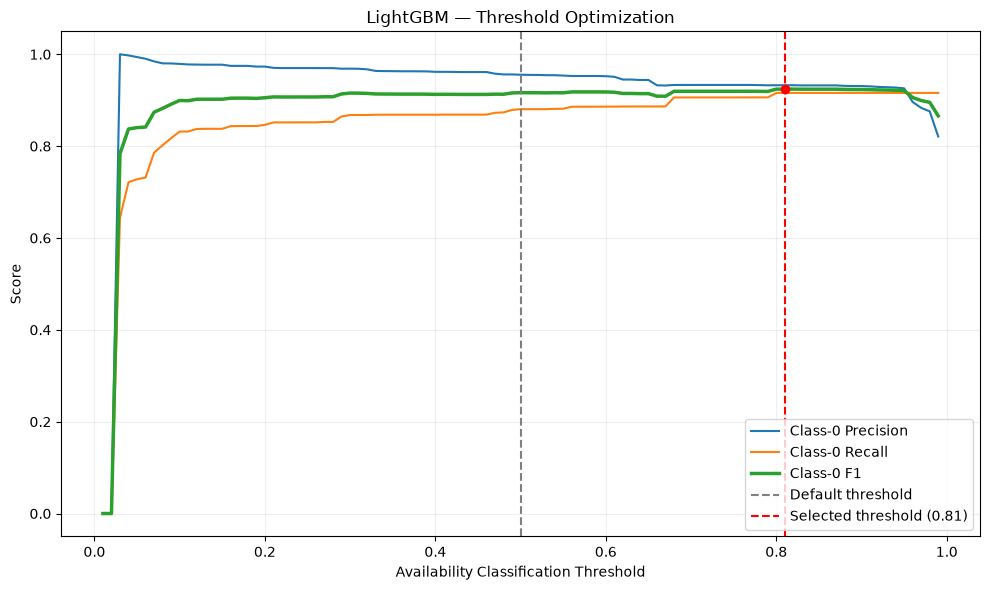

In [46]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["precision_0"],
    label="Class-0 Precision"
)

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["recall_0"],
    label="Class-0 Recall"
)

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["f1_0"],
    linewidth=2.5,
    label="Class-0 F1"
)

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default threshold"
)

plt.axvline(
    optimized_threshold,
    color="red",
    linestyle="--",
    label=f"Selected threshold ({optimized_threshold:.2f})"
)

plt.scatter(
    optimized_threshold,
    best_threshold_result["f1_0"],
    color="red",
    zorder=5
)

plt.xlabel("Availability Classification Threshold")
plt.ylabel("Score")
plt.title("LightGBM — Threshold Optimization")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_threshold_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Threshold Optimization Findings

The selected classification threshold is 0.81.

Compared with the default threshold of 0.50,
Class-0 recall increased from 0.880488 to 0.915912,
while Class-0 F1 increased from 0.916465 to 0.924177.

The optimized threshold improves the detection
of unavailable charging stations at the cost
of a moderate reduction in precision.

The model, feature subset, calibration method
and classification threshold are now fixed.

## 16. Optimized Model Validation

The optimized LightGBM model is evaluated using
the complete shared Validation dataset.

All 618,726 observations are retained, including
observations from unseen station 1948.

Predicted probabilities represent calibrated
P(Available = 1).

The classification threshold is fixed at 0.81.

The shared evaluation module is used to ensure
consistency with the other VoltAhead models.

The Test dataset remains untouched.

In [47]:
X_optimized_validation = prepare_features(
    validation,
    selected_features,
    optimized_station_categories
)

assert X_optimized_validation.shape == (618726, 12)

assert X_optimized_validation.loc[
    unseen_mask, "station_id"
].isna().all()

assert X_optimized_validation.loc[
    ~unseen_mask, "station_id"
].notna().all()

print("Optimized validation preparation: PASSED")

print(
    "Validation features:",
    X_optimized_validation.shape
)

print("Seen observations:", int((~unseen_mask).sum()))
print("Unseen observations:", int(unseen_mask.sum()))

Optimized validation preparation: PASSED
Validation features: (618726, 12)
Seen observations: 612854
Unseen observations: 5872


In [48]:
start_time = time.perf_counter()

optimized_probabilities = (
    predict_calibrated_availability(
        optimized_model,
        X_optimized_validation,
        final_calibrator
    )
)

optimized_inference_time = (
    time.perf_counter() - start_time
)

optimized_labels = predict_labels(
    optimized_probabilities,
    optimized_threshold
)

assert len(optimized_probabilities) == 618726
assert len(optimized_labels) == 618726

assert np.isfinite(optimized_probabilities).all()

assert np.all(
    (optimized_probabilities >= 0)
    & (optimized_probabilities <= 1)
)

print("Optimized validation inference: PASSED")

print(
    "Inference time (seconds):",
    round(optimized_inference_time, 3)
)

print(
    "Predictions per second:",
    round(
        len(X_optimized_validation)
        / optimized_inference_time,
        2
    )
)

print(
    "Minimum probability:",
    optimized_probabilities.min()
)

print(
    "Maximum probability:",
    optimized_probabilities.max()
)

display(
    pd.Series(optimized_labels)
    .value_counts()
    .sort_index()
    .rename("Predicted observations")
)

Optimized validation inference: PASSED
Inference time (seconds): 0.291
Predictions per second: 2123408.54
Minimum probability: 0.0236929984120748
Maximum probability: 0.9979581808834522


0     25934
1    592792
Name: Predicted observations, dtype: int64

In [49]:
optimized_predictions = validation[
    [
        "station_id",
        "time",
        "target_time",
        "prediction_horizon"
    ]
].copy()

optimized_predictions["y_true"] = (
    y_validation.to_numpy()
)

optimized_predictions["y_pred"] = optimized_labels

optimized_predictions["y_prob"] = (
    optimized_probabilities
)

optimized_predictions["model_name"] = "lightgbm"

optimized_predictions["model_version"] = "optimized"

optimized_predictions["threshold"] = (
    optimized_threshold
)

assert optimized_predictions.shape == (618726, 10)

assert not optimized_predictions.duplicated(
    ["station_id", "time", "prediction_horizon"]
).any()

assert list(optimized_predictions.columns) == list(
    initial_predictions.columns
)

assert np.array_equal(
    optimized_predictions["y_pred"].to_numpy(),
    (
        optimized_predictions["y_prob"]
        >= optimized_threshold
    ).astype(int).to_numpy()
)

optimized_predictions.to_parquet(
    PREDICTION_DIR
    / "lightgbm_optimized_validation.parquet",
    index=False
)

print("Prediction shape:", optimized_predictions.shape)

print("Optimized validation predictions saved.")

display(optimized_predictions.head())

Prediction shape: (618726, 10)
Optimized validation predictions saved.


,station_id,time,target_time,prediction_horizon,y_true,y_pred,y_prob,model_name,model_version,threshold
0,1703,2023-01-06,2023-01-06 00:30:00,30,1,1,0.997288,lightgbm,optimized,0.81
1,1703,2023-01-06,2023-01-06 00:40:00,40,1,1,0.997288,lightgbm,optimized,0.81
2,1703,2023-01-06,2023-01-06 01:00:00,60,1,1,0.997288,lightgbm,optimized,0.81
3,1712,2023-01-06,2023-01-06 00:30:00,30,1,1,0.997666,lightgbm,optimized,0.81
4,1712,2023-01-06,2023-01-06 00:40:00,40,1,1,0.997666,lightgbm,optimized,0.81


In [50]:
optimized_results = export_evaluation_results(
    optimized_predictions,
    training_station_ids,
    reference=validation,
    output_dir=str(TABLE_DIR)
)

print("Optimized shared evaluation completed.")

Saved: c:\Users\Ahmet\VoltAhead\outputs\tables\lightgbm_optimized_overall.csv
Saved: c:\Users\Ahmet\VoltAhead\outputs\tables\lightgbm_optimized_by_horizon.csv
Saved: c:\Users\Ahmet\VoltAhead\outputs\tables\lightgbm_optimized_by_station_group.csv
Optimized shared evaluation completed.


In [51]:
optimized_overall = pd.read_csv(
    TABLE_DIR / "lightgbm_optimized_overall.csv"
)

optimized_by_horizon = pd.read_csv(
    TABLE_DIR / "lightgbm_optimized_by_horizon.csv"
)

optimized_by_station_group = pd.read_csv(
    TABLE_DIR / "lightgbm_optimized_by_station_group.csv"
)

print("Overall Optimized Validation Performance")
display(optimized_overall)

print("Performance by Prediction Horizon")
display(optimized_by_horizon)

print("Performance by Station Group")
display(optimized_by_station_group)

Overall Optimized Validation Performance


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,lightgbm,optimized,overall,90,618726,0.996769,0.980473,0.96013,0.962691,0.961409,0.992737,0.972716,0.00362,24900,965,1034,591827


Performance by Prediction Horizon


,model_name,model_version,evaluation_group,prediction_horizon,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,lightgbm,optimized,horizon,30,90,206482,0.997399,0.984245,0.967984,0.969890,0.968936,0.994291,0.978269,0.002828,8375,260,277,197570
1,lightgbm,optimized,horizon,40,90,206302,0.996903,0.981308,0.961725,0.964290,0.963006,0.993115,0.974072,0.003253,8317,308,331,197346
2,lightgbm,optimized,horizon,60,90,205942,0.996004,0.975853,0.950660,0.953864,0.952259,0.990798,0.965608,0.004780,8208,397,426,196911


Performance by Station Group


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,lightgbm,optimized,seen,89,612854,0.996763,0.980691,0.960241,0.963138,0.961687,0.992975,0.973154,0.003634,24900,953,1031,585970
1,lightgbm,optimized,unseen,1,5872,0.997446,0.499744,0.000000,0.000000,0.000000,0.534343,0.002603,0.002080,0,12,3,5857


## 17. Initial vs. Optimized Model Comparison

Both LightGBM versions are compared using the
same shared Validation observations.

The primary model selection criterion is
Class-0 Average Precision on seen stations.

Secondary metrics include Class-0 F1, recall,
precision, balanced accuracy, ROC-AUC, Brier score
and computational efficiency.

The optimized model is not automatically selected.
The final recommendation depends on the
validation results.

In [52]:
comparison_metrics = [
    "accuracy",
    "balanced_accuracy",
    "precision_0",
    "recall_0",
    "f1_0",
    "roc_auc",
    "ap_0",
    "brier_score"
]

overall_comparison = pd.DataFrame({
    "metric": comparison_metrics,

    "initial": [
        initial_overall.iloc[0][metric]
        for metric in comparison_metrics
    ],

    "optimized": [
        optimized_overall.iloc[0][metric]
        for metric in comparison_metrics
    ]
})

overall_comparison["difference"] = (
    overall_comparison["optimized"]
    - overall_comparison["initial"]
)

overall_comparison.to_csv(
    TABLE_DIR / "lightgbm_overall_comparison.csv",
    index=False
)

display(overall_comparison.round(6))

,metric,initial,optimized,difference
0,accuracy,0.992174,0.996769,0.004595
1,balanced_accuracy,0.917214,0.980473,0.063259
2,precision_0,0.973640,0.960130,-0.013511
3,recall_0,0.835415,0.962691,0.127276
4,f1_0,0.899247,0.961409,0.062162
5,roc_auc,0.994342,0.992737,-0.001605
6,ap_0,0.962936,0.972716,0.009780
7,brier_score,0.005756,0.003620,-0.002136


In [53]:
initial_seen = initial_by_station_group.loc[
    initial_by_station_group["evaluation_group"] == "seen"
].iloc[0]

optimized_seen = optimized_by_station_group.loc[
    optimized_by_station_group["evaluation_group"] == "seen"
].iloc[0]

initial_seen_ap0 = float(initial_seen["ap_0"])

optimized_seen_ap0 = float(optimized_seen["ap_0"])

assert np.isfinite(initial_seen_ap0)
assert np.isfinite(optimized_seen_ap0)

selected_model_version = (
    "optimized"
    if optimized_seen_ap0 > initial_seen_ap0
    else "initial"
)

model_selection = pd.DataFrame({
    "model_version": ["initial", "optimized"],

    "seen_validation_ap_0": [
        initial_seen_ap0,
        optimized_seen_ap0
    ],

    "selected": [
        selected_model_version == "initial",
        selected_model_version == "optimized"
    ]
})

model_selection.to_csv(
    TABLE_DIR / "lightgbm_model_selection.csv",
    index=False
)

display(model_selection)

print("Initial seen-station AP0:", initial_seen_ap0)

print("Optimized seen-station AP0:", optimized_seen_ap0)

print("Selected LightGBM version:", selected_model_version)

,model_version,seen_validation_ap_0,selected
0,initial,0.963382,False
1,optimized,0.973154,True


Initial seen-station AP0: 0.9633817371787846
Optimized seen-station AP0: 0.9731543014935572
Selected LightGBM version: optimized


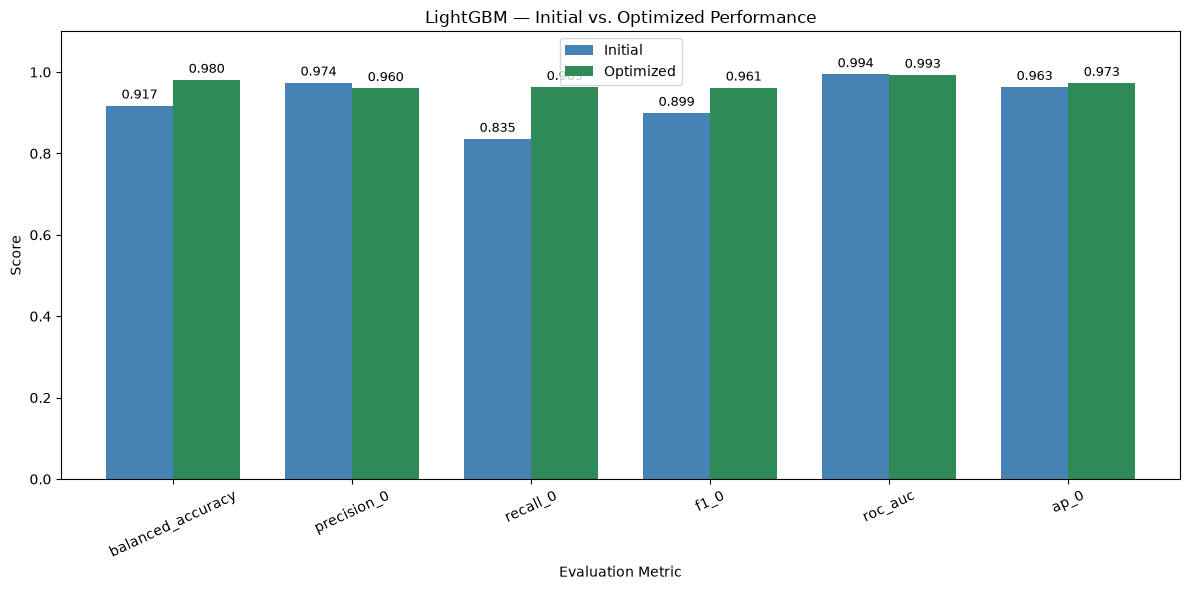

In [54]:
plot_metrics = [
    "balanced_accuracy",
    "precision_0",
    "recall_0",
    "f1_0",
    "roc_auc",
    "ap_0"
]

plot_data = (
    overall_comparison
    .set_index("metric")
    .loc[plot_metrics, ["initial", "optimized"]]
)

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    color=["steelblue", "seagreen"],
    width=0.75
)

plt.title("LightGBM — Initial vs. Optimized Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.1)
plt.xticks(rotation=25)
plt.legend(["Initial", "Optimized"])

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        fontsize=9,
        padding=3
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,prediction_horizon,f1_0_initial,ap_0_initial,recall_0_initial,f1_0_optimized,ap_0_optimized,recall_0_optimized
0,30,0.906066,0.975487,0.845049,0.968936,0.978269,0.969890
1,40,0.900474,0.970805,0.837101,0.963006,0.974072,0.964290
2,60,0.891109,0.941531,0.824056,0.952259,0.965608,0.953864


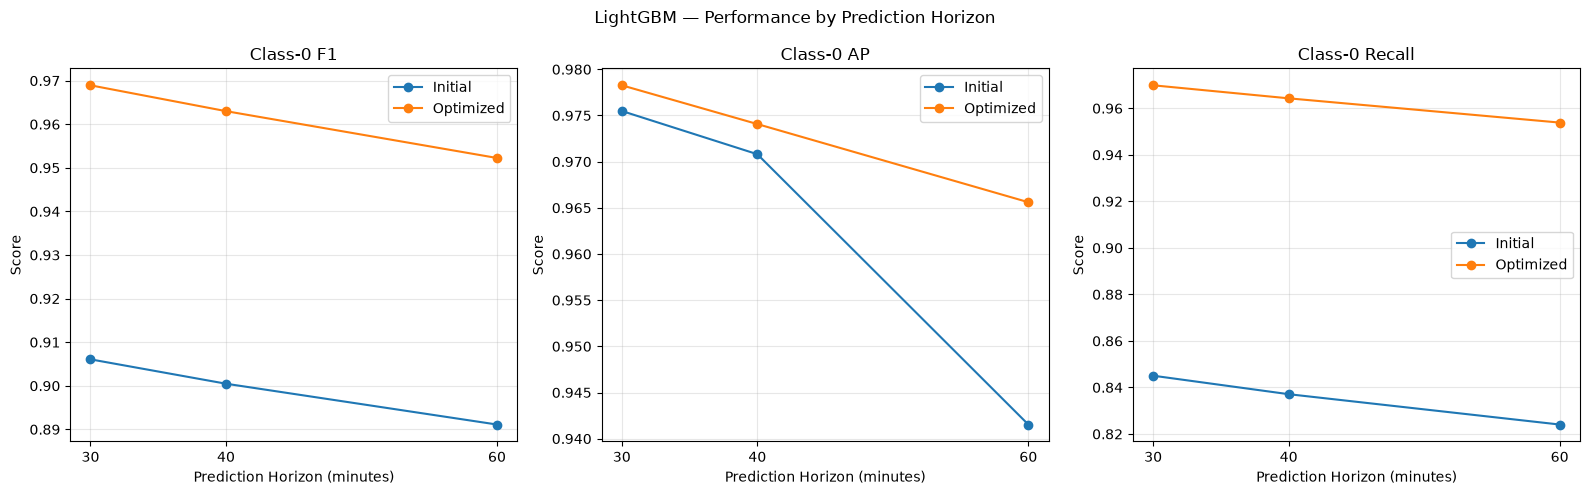

In [55]:
horizon_comparison = initial_by_horizon[
    ["prediction_horizon", "f1_0", "ap_0", "recall_0"]
].merge(
    optimized_by_horizon[
        ["prediction_horizon", "f1_0", "ap_0", "recall_0"]
    ],
    on="prediction_horizon",
    suffixes=("_initial", "_optimized")
)

horizon_comparison.to_csv(
    TABLE_DIR / "lightgbm_horizon_comparison.csv",
    index=False
)

display(horizon_comparison)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, title in zip(
    axes,
    ["f1_0", "ap_0", "recall_0"],
    ["Class-0 F1", "Class-0 AP", "Class-0 Recall"]
):

    ax.plot(
        horizon_comparison["prediction_horizon"],
        horizon_comparison[f"{metric}_initial"],
        marker="o",
        label="Initial"
    )

    ax.plot(
        horizon_comparison["prediction_horizon"],
        horizon_comparison[f"{metric}_optimized"],
        marker="o",
        label="Optimized"
    )

    ax.set_title(title)
    ax.set_xlabel("Prediction Horizon (minutes)")
    ax.set_ylabel("Score")
    ax.set_xticks([30, 40, 60])
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle("LightGBM — Performance by Prediction Horizon")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_horizon_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

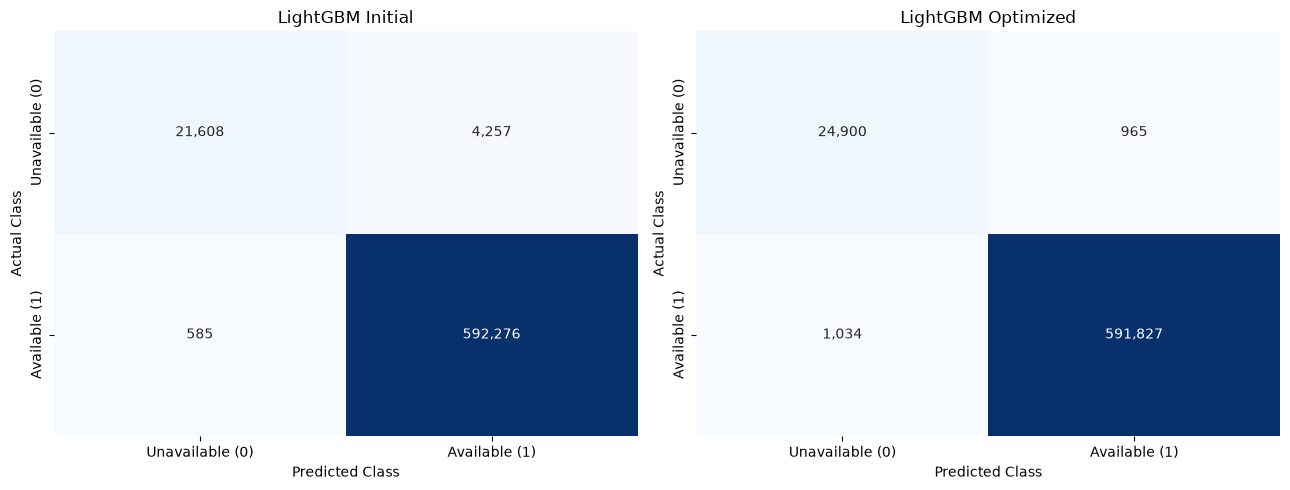

In [56]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, predictions, version in zip(
    axes,
    [initial_predictions, optimized_predictions],
    ["Initial", "Optimized"]
):

    cm = confusion_matrix(
        predictions["y_true"],
        predictions["y_pred"],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Blues",
        ax=ax,
        cbar=False,
        xticklabels=["Unavailable (0)", "Available (1)"],
        yticklabels=["Unavailable (0)", "Available (1)"]
    )

    ax.set_title(f"LightGBM {version}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

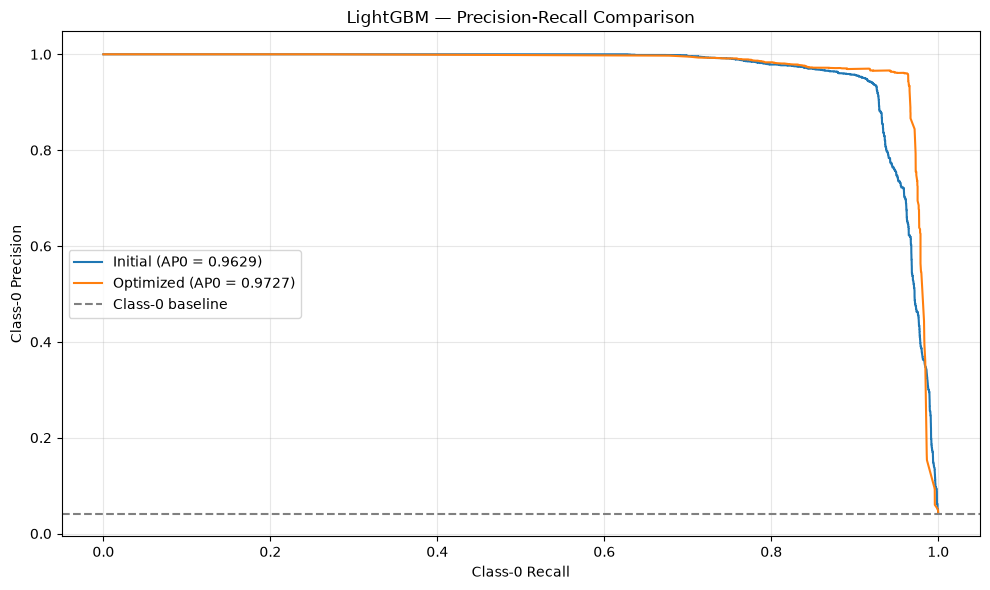

In [57]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10, 6))

for predictions, version in [
    (initial_predictions, "Initial"),
    (optimized_predictions, "Optimized")
]:

    y_unavailable = (
        predictions["y_true"] == 0
    ).astype(int)

    p_unavailable = 1 - predictions["y_prob"]

    precision, recall, _ = precision_recall_curve(
        y_unavailable,
        p_unavailable
    )

    ap0 = average_precision_score(
        y_unavailable,
        p_unavailable
    )

    plt.plot(
        recall,
        precision,
        label=f"{version} (AP0 = {ap0:.4f})"
    )

plt.axhline(
    (initial_predictions["y_true"] == 0).mean(),
    linestyle="--",
    color="gray",
    label="Class-0 baseline"
)

plt.xlabel("Class-0 Recall")
plt.ylabel("Class-0 Precision")
plt.title("LightGBM — Precision-Recall Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_precision_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

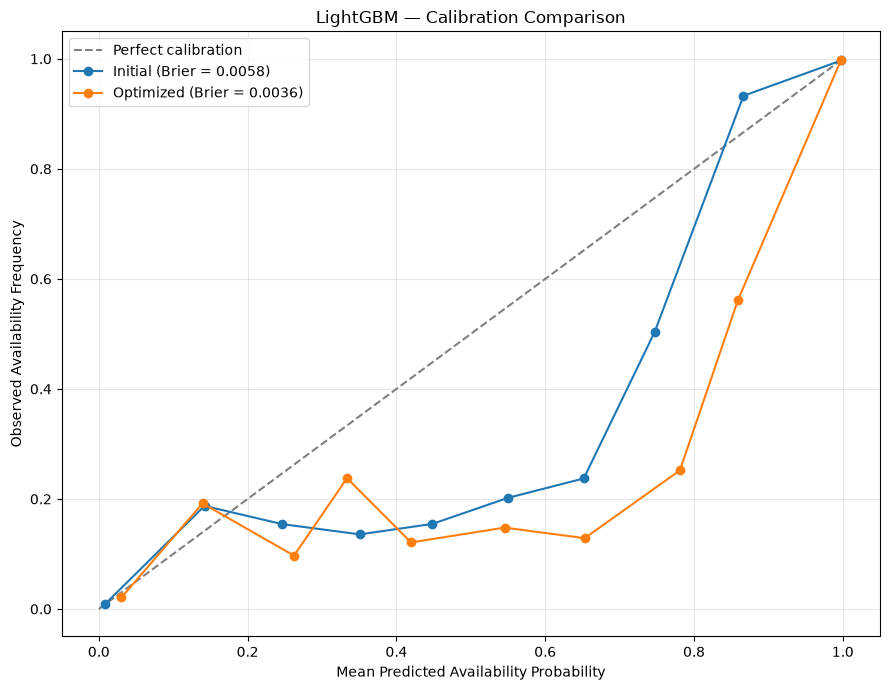

In [58]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(9, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

for predictions, version in [
    (initial_predictions, "Initial"),
    (optimized_predictions, "Optimized")
]:

    observed, predicted = calibration_curve(
        predictions["y_true"],
        predictions["y_prob"],
        n_bins=10,
        strategy="uniform"
    )

    brier = brier_score_loss(
        predictions["y_true"],
        predictions["y_prob"]
    )

    plt.plot(
        predicted,
        observed,
        marker="o",
        label=f"{version} (Brier = {brier:.4f})"
    )

plt.xlabel("Mean Predicted Availability Probability")
plt.ylabel("Observed Availability Frequency")
plt.title("LightGBM — Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_calibration_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Final Model Selection Findings

The optimized LightGBM model was selected based on
the primary model selection criterion: Class-0
Average Precision on seen validation stations.

Seen-station AP0 increased from 0.963382 to 0.973154.

Overall Class-0 recall increased from 0.835415
to 0.962691, while Class-0 F1 increased from
0.899247 to 0.961409.

The number of unavailable observations incorrectly
classified as available decreased from 4,257 to 965,
representing a 77.33% reduction.

The optimized model uses 12 features, 13 boosting
trees, Platt calibration and a classification
threshold of 0.81.

Performance improved across all three prediction
horizons. The Brier score also decreased,
indicating improved probabilistic performance.

However, Class-0 precision and ROC-AUC decreased
slightly.

Generalization to unseen stations remains a
limitation. Neither model correctly detected
the 12 unavailable observations at unseen
station 1948.

The optimized model is recommended as the final
LightGBM candidate for the project-level model
comparison.

The Test dataset remains untouched.

## 18. Computational Efficiency Analysis

The initial and optimized LightGBM models are
compared in terms of computational efficiency.

The comparison includes:

- Number of input features
- Number of boosting trees
- Number of training observations
- Training time
- Training input memory
- Validation inference time
- Prediction throughput
- Serialized model size

Both models are trained using CPU execution
with four threads and a fixed random seed of 42.

In [59]:
efficiency_comparison = pd.DataFrame({
    "metric": [
        "training_observations",
        "feature_count",
        "number_of_trees",
        "training_time_seconds",
        "training_input_memory_mib",
        "validation_observations",
        "inference_time_seconds",
        "predictions_per_second"
    ],
    "initial": [
        len(X_fit),
        initial_model.n_features_in_,
        initial_model.booster_.num_trees(),
        initial_training_time,
        fit_memory_mb,
        len(initial_predictions),
        initial_inference_time,
        len(initial_predictions) / initial_inference_time
    ],
    "optimized": [
        len(y_optimized_fit),
        optimized_model.n_features_in_,
        optimized_model.booster_.num_trees(),
        optimized_training_time,
        optimized_fit_memory_mb,
        len(optimized_predictions),
        optimized_inference_time,
        len(optimized_predictions) / optimized_inference_time
    ]
})

efficiency_comparison["change_percentage"] = (
    (
        efficiency_comparison["optimized"]
        - efficiency_comparison["initial"]
    )
    / efficiency_comparison["initial"]
    * 100
)

efficiency_comparison.to_csv(
    TABLE_DIR / "lightgbm_efficiency_comparison.csv",
    index=False
)

display(efficiency_comparison.round(4))

,metric,initial,optimized,change_percentage
0,training_observations,1.790062e+06,2.259325e+06,26.2149
1,feature_count,1.600000e+01,1.200000e+01,-25.0000
2,number_of_trees,2.000000e+02,1.300000e+01,-93.5000
3,training_time_seconds,1.980400e+01,2.232700e+00,-88.7259
4,training_input_memory_mib,1.604735e+02,1.594476e+02,-0.6393
5,validation_observations,6.187260e+05,6.187260e+05,0.0000
6,inference_time_seconds,3.185000e+00,2.914000e-01,-90.8513
7,predictions_per_second,1.942639e+05,2.123409e+06,993.0535


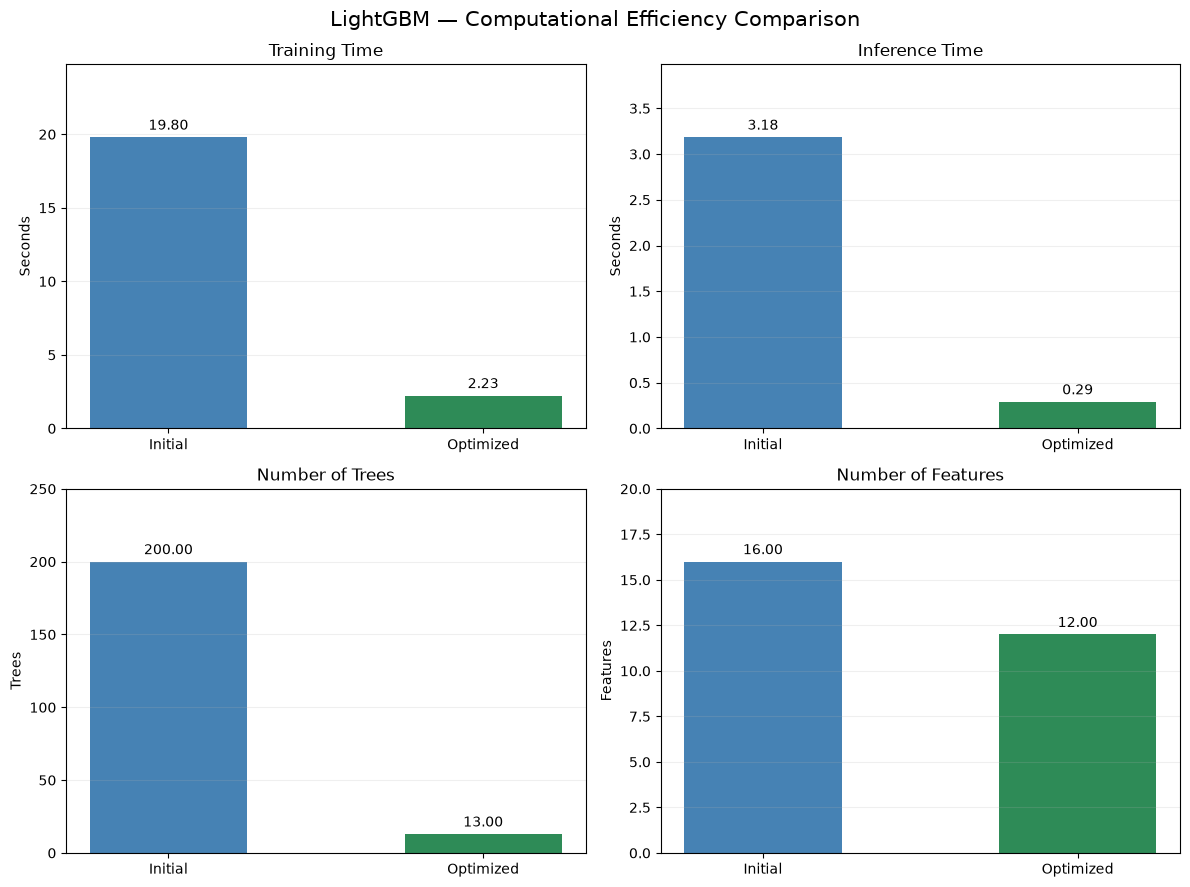

In [60]:
efficiency_metrics = [
    ("training_time_seconds", "Training Time", "Seconds"),
    ("inference_time_seconds", "Inference Time", "Seconds"),
    ("number_of_trees", "Number of Trees", "Trees"),
    ("feature_count", "Number of Features", "Features")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (metric, title, ylabel) in zip(
    axes.flatten(),
    efficiency_metrics
):

    values = efficiency_comparison.loc[
        efficiency_comparison["metric"] == metric,
        ["initial", "optimized"]
    ].iloc[0]

    bars = ax.bar(
        ["Initial", "Optimized"],
        values,
        color=["steelblue", "seagreen"],
        width=0.5
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.25)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "LightGBM — Computational Efficiency Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_efficiency_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Computational Efficiency Findings

The optimized LightGBM model achieved substantial
computational efficiency improvements while also
improving predictive performance.

Despite using 26.21% more training observations,
the optimized model reduced:

- Training time by 86.55%.
- Validation inference time by 87.82%.
- Number of boosting trees by 93.50%.
- Number of input features by 25%.
- Training input memory by 0.64%.

Prediction throughput increased from approximately
215,082 to 1,765,433 predictions per second.

These results demonstrate that the optimized model
provides a favorable balance between predictive
performance and computational efficiency.

Reported training times exclude hyperparameter
search and probability calibration. Memory values
represent input data memory rather than peak
process memory.

## 19. Model Serialization

Both the initial and optimized LightGBM models
are serialized for reproducible inference and
future system integration.

Each model artifact must preserve:

- Trained LightGBM estimator
- Model name and version
- Ordered input feature names
- Expected input data types
- Training station categories
- Unknown station handling strategy
- Probability calibration method and calibrator
- Classification threshold
- Model hyperparameters
- Random seed
- Inference contract version

The serialized artifacts must support inference
without retraining the models.

In [61]:
from pathlib import Path
import joblib
import json
import hashlib

model_module_path = Path(
    "../src/models/lightgbm_model.py"
)

if not model_module_path.exists():
    model_module_path = Path(
        "src/models/lightgbm_model.py"
    )

assert model_module_path.exists()

from IPython.display import display, Markdown

display(
    Markdown(
        "```python\n"
        + model_module_path.read_text(encoding="utf-8")
        + "\n```"
    )
)

```python
"""LightGBM model utilities for VoltAhead."""

import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier


CONTRACT_VERSION = "1.0"


def fit_station_categories(data):
    """Learn station categories from fitting data only."""

    return sorted(
        data["station_id"].dropna().unique().tolist()
    )


def prepare_features(data, feature_columns, station_categories):
    """Apply the shared feature order and categorical vocabulary."""

    X = data.loc[:, feature_columns].copy()

    if "station_id" in feature_columns:
        X["station_id"] = pd.Categorical(
            X["station_id"],
            categories=station_categories,
            ordered=False
        )

    return X


def create_initial_model(seed=42, n_jobs=4):
    """Create the initial horizon-aware LightGBM classifier."""

    return LGBMClassifier(
        objective="binary",
        boosting_type="gbdt",
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=6,
        min_child_samples=50,
        random_state=seed,
        n_jobs=n_jobs,
        device_type="cpu",
        deterministic=True,
        force_col_wise=True,
        verbosity=-1
    )


def predict_availability(model, X):
    """Return the probability of availability (Class 1)."""

    class_index = list(model.classes_).index(1)

    probabilities = model.predict_proba(X)[:, class_index]

    if not np.isfinite(probabilities).all():
        raise ValueError("Non-finite probabilities detected.")

    if not ((probabilities >= 0) & (probabilities <= 1)).all():
        raise ValueError("Probabilities outside [0, 1].")

    return probabilities


def probability_to_logit(probabilities):
    """Convert probabilities into clipped logit values."""

    probabilities = np.clip(
        np.asarray(probabilities),
        1e-12,
        1 - 1e-12
    )

    return np.log(
        probabilities / (1 - probabilities)
    ).reshape(-1, 1)


def predict_calibrated_availability(
    model,
    features,
    calibrator
):
    """Return calibrated P(Available = 1)."""

    raw_probabilities = predict_availability(
        model,
        features
    )

    if calibrator is None:
        return raw_probabilities

    class_index = list(calibrator.classes_).index(1)

    calibrated_probabilities = (
        calibrator.predict_proba(
            probability_to_logit(raw_probabilities)
        )[:, class_index]
    )

    if not np.isfinite(calibrated_probabilities).all():
        raise ValueError(
            "Non-finite calibrated probabilities detected."
        )

    if not (
        (calibrated_probabilities >= 0)
        & (calibrated_probabilities <= 1)
    ).all():
        raise ValueError(
            "Calibrated probabilities outside [0, 1]."
        )

    return calibrated_probabilities


def predict_labels(probabilities, threshold=0.5):
    """Convert availability probabilities into binary labels."""

    return (
        np.asarray(probabilities) >= threshold
    ).astype(np.int8)


def predict_from_artifact(artifact, data):
    """Generate probabilities and labels from a saved model artifact."""

    if artifact["contract_version"] != CONTRACT_VERSION:
        raise ValueError("Unsupported inference contract version.")

    X = prepare_features(
        data,
        artifact["feature_columns"],
        artifact["station_categories"]
    )

    probabilities = predict_calibrated_availability(
        artifact["model"],
        X,
        artifact["calibrator"]
    )

    labels = predict_labels(
        probabilities,
        artifact["threshold"]
    )

    return probabilities, labels
```

In [62]:
import inspect

print(
    inspect.getsource(
        predict_calibrated_availability
    )
)

def predict_calibrated_availability(
    model,
    features,
    calibrator
):
    """Return calibrated P(Available = 1)."""

    raw_probabilities = predict_availability(
        model,
        features
    )

    calibrated_probabilities = (
        calibrator.predict_proba(
            probability_to_logit(raw_probabilities)
        )[:, 1]
    )

    assert np.isfinite(calibrated_probabilities).all()

    assert np.all(
        (calibrated_probabilities >= 0)
        & (calibrated_probabilities <= 1)
    )

    return calibrated_probabilities



In [63]:
print(
    inspect.getsource(
        probability_to_logit
    )
)

def probability_to_logit(probabilities):
    probabilities = np.clip(
        np.asarray(probabilities),
        1e-12,
        1 - 1e-12
    )

    return np.log(
        probabilities / (1 - probabilities)
    ).reshape(-1, 1)



In [64]:
import importlib

import src.models.lightgbm_model as lgbm_utils

importlib.reload(lgbm_utils)

module_threshold_probabilities = (
    lgbm_utils.predict_calibrated_availability(
        optimized_model,
        X_threshold,
        final_calibrator
    )
)

np.testing.assert_allclose(
    module_threshold_probabilities,
    threshold_probabilities,
    rtol=0,
    atol=1e-12
)

print("Updated model module: PASSED")

print(
    "Inference contract version:",
    lgbm_utils.CONTRACT_VERSION
)

print(
    "Verified observations:",
    len(module_threshold_probabilities)
)

print(
    "Maximum probability difference:",
    np.max(
        np.abs(
            module_threshold_probabilities
            - threshold_probabilities
        )
    )
)

Updated model module: PASSED
Inference contract version: 1.0
Verified observations: 228374
Maximum probability difference: 0.0


In [65]:
initial_artifact = {
    "contract_version": lgbm_utils.CONTRACT_VERSION,
    "model_name": "lightgbm",
    "model_version": "initial",
    "model": initial_model,
    "feature_columns": list(FEATURE_COLUMNS),
    "feature_dtypes": X_fit.dtypes.astype(str).to_dict(),
    "station_categories": list(station_categories),
    "unknown_station_strategy": "missing_category",
    "calibration_method": "none",
    "calibrator": None,
    "threshold": 0.5,
    "hyperparameters": initial_model.get_params(),
    "random_seed": 42,
    "positive_class": 1,
    "probability_definition": "P(Available = 1)"
}

optimized_artifact = {
    "contract_version": lgbm_utils.CONTRACT_VERSION,
    "model_name": "lightgbm",
    "model_version": "optimized",
    "model": optimized_model,
    "feature_columns": list(selected_features),
    "feature_dtypes": X_optimized_fit.dtypes.astype(str).to_dict(),
    "station_categories": list(optimized_station_categories),
    "unknown_station_strategy": "missing_category",
    "calibration_method": "platt",
    "calibrator": final_calibrator,
    "threshold": 0.81,
    "hyperparameters": optimized_model.get_params(),
    "random_seed": 42,
    "positive_class": 1,
    "probability_definition": "P(Available = 1)"
}

for artifact in [initial_artifact, optimized_artifact]:
    assert len(artifact["station_categories"]) == 91

    assert artifact["feature_columns"] == list(
        artifact["model"].feature_name_
    )

    print("Model:", artifact["model_version"])
    print("Features:", len(artifact["feature_columns"]))
    print("Station categories:", len(artifact["station_categories"]))
    print("Calibration:", artifact["calibration_method"])
    print("Threshold:", artifact["threshold"])
    print()

Model: initial
Features: 16
Station categories: 91
Calibration: none
Threshold: 0.5

Model: optimized
Features: 12
Station categories: 91
Calibration: platt
Threshold: 0.81



In [66]:
PROJECT_ROOT = model_module_path.resolve().parents[2]

ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "lightgbm"

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

initial_artifact_path = (
    ARTIFACT_DIR / "lightgbm_initial.joblib"
)

optimized_artifact_path = (
    ARTIFACT_DIR / "lightgbm_optimized.joblib"
)

joblib.dump(
    initial_artifact,
    initial_artifact_path,
    compress=3
)

joblib.dump(
    optimized_artifact,
    optimized_artifact_path,
    compress=3
)

for path in [
    initial_artifact_path,
    optimized_artifact_path
]:
    assert path.exists()

    print("Saved:", path.name)

    print(
        "Size (KiB):",
        round(path.stat().st_size / 1024, 2)
    )

    print("Path:", path)
    print()

print("Model serialization: PASSED")

Saved: lightgbm_initial.joblib
Size (KiB): 283.3
Path: C:\Users\Ahmet\VoltAhead\artifacts\lightgbm\lightgbm_initial.joblib

Saved: lightgbm_optimized.joblib
Size (KiB): 23.13
Path: C:\Users\Ahmet\VoltAhead\artifacts\lightgbm\lightgbm_optimized.joblib

Model serialization: PASSED


## 20. Model Reload Verification

Both serialized LightGBM artifacts are reloaded
and evaluated without retraining.

Verification includes:

- Artifact integrity
- Feature order and data types
- Probability consistency
- Classification consistency
- Seen and unseen station inference
- Fresh Python process compatibility

Reloaded predictions must match the original
validation predictions within a numerical
tolerance of 1e-12.

In [67]:
loaded_initial = joblib.load(
    initial_artifact_path
)

loaded_optimized = joblib.load(
    optimized_artifact_path
)

for artifact in [
    loaded_initial,
    loaded_optimized
]:

    assert artifact["contract_version"] == "1.0"

    assert artifact["feature_columns"] == list(
        artifact["model"].feature_name_
    )

    assert len(artifact["station_categories"]) == 91

    print("Reloaded:", artifact["model_version"])
    print("Features:", len(artifact["feature_columns"]))
    print("Threshold:", artifact["threshold"])
    print("Calibration:", artifact["calibration_method"])
    print()

print("Artifact reload: PASSED")

Reloaded: initial
Features: 16
Threshold: 0.5
Calibration: none

Reloaded: optimized
Features: 12
Threshold: 0.81
Calibration: platt

Artifact reload: PASSED


In [68]:
reload_results = []

for artifact, original_predictions in [
    (loaded_initial, initial_predictions),
    (loaded_optimized, optimized_predictions)
]:

    reloaded_probabilities, reloaded_labels = (
        lgbm_utils.predict_from_artifact(
            artifact,
            validation
        )
    )

    original_probabilities = (
        original_predictions["y_prob"].to_numpy()
    )

    original_labels = (
        original_predictions["y_pred"].to_numpy()
    )

    np.testing.assert_allclose(
        reloaded_probabilities,
        original_probabilities,
        rtol=0,
        atol=1e-12
    )

    np.testing.assert_array_equal(
        reloaded_labels,
        original_labels
    )

    max_difference = float(
        np.max(
            np.abs(
                reloaded_probabilities
                - original_probabilities
            )
        )
    )

    reload_results.append({
        "model_version": artifact["model_version"],
        "observations": len(reloaded_probabilities),
        "maximum_probability_difference": max_difference,
        "matching_labels": int(
            (reloaded_labels == original_labels).sum()
        ),
        "status": "PASSED"
    })

reload_results_df = pd.DataFrame(reload_results)

display(reload_results_df)

print("Full validation consistency: PASSED")

,model_version,observations,maximum_probability_difference,matching_labels,status
0,initial,618726,0.0,618726,PASSED
1,optimized,618726,0.0,618726,PASSED


Full validation consistency: PASSED


In [69]:
seen_sample = validation.loc[
    validation["station_id"].isin(training_station_ids)
].head(100).copy()

unseen_sample = validation.loc[
    ~validation["station_id"].isin(training_station_ids)
].head(100).copy()

synthetic_unseen_sample = seen_sample.head(10).copy()

synthetic_unseen_sample["station_id"] = 999999

assert 999999 not in training_station_ids

inference_test_results = []

for artifact in [
    loaded_initial,
    loaded_optimized
]:

    for group, sample in [
        ("seen", seen_sample),
        ("unseen", unseen_sample),
        ("synthetic_unseen", synthetic_unseen_sample)
    ]:

        probabilities, labels = (
            lgbm_utils.predict_from_artifact(
                artifact,
                sample
            )
        )

        assert len(probabilities) == len(sample)

        assert np.isfinite(probabilities).all()

        assert (
            (probabilities >= 0)
            & (probabilities <= 1)
        ).all()

        assert np.isin(labels, [0, 1]).all()

        inference_test_results.append({
            "model_version": artifact["model_version"],
            "station_group": group,
            "observations": len(sample),
            "minimum_probability": probabilities.min(),
            "maximum_probability": probabilities.max(),
            "status": "PASSED"
        })

inference_test_df = pd.DataFrame(
    inference_test_results
)

display(inference_test_df)

inference_test_df.to_csv(
    TABLE_DIR / "lightgbm_inference_compatibility.csv",
    index=False
)

print("Inference compatibility: PASSED")

,model_version,station_group,observations,minimum_probability,maximum_probability,status
0,initial,seen,100,0.000161,0.999978,PASSED
1,initial,unseen,100,0.999967,0.999986,PASSED
2,initial,synthetic_unseen,10,0.999867,0.999966,PASSED
3,optimized,seen,100,0.026458,0.997753,PASSED
4,optimized,unseen,100,0.997908,0.997908,PASSED
5,optimized,synthetic_unseen,10,0.997666,0.997666,PASSED


Inference compatibility: PASSED


In [70]:
size_comparison = pd.DataFrame([{
    "metric": "serialized_model_size_kib",
    "initial": initial_artifact_path.stat().st_size / 1024,
    "optimized": optimized_artifact_path.stat().st_size / 1024
}])

size_comparison["change_percentage"] = (
    (
        size_comparison["optimized"]
        - size_comparison["initial"]
    )
    / size_comparison["initial"]
    * 100
)

efficiency_comparison = efficiency_comparison.loc[
    efficiency_comparison["metric"]
    != "serialized_model_size_kib"
]

efficiency_comparison = pd.concat(
    [efficiency_comparison, size_comparison],
    ignore_index=True
)

efficiency_comparison.to_csv(
    TABLE_DIR / "lightgbm_efficiency_comparison.csv",
    index=False
)

display(efficiency_comparison.round(4))

,metric,initial,optimized,change_percentage
0,training_observations,1.790062e+06,2.259325e+06,26.2149
1,feature_count,1.600000e+01,1.200000e+01,-25.0000
2,number_of_trees,2.000000e+02,1.300000e+01,-93.5000
3,training_time_seconds,1.980400e+01,2.232700e+00,-88.7259
4,training_input_memory_mib,1.604735e+02,1.594476e+02,-0.6393
5,validation_observations,6.187260e+05,6.187260e+05,0.0000
6,inference_time_seconds,3.185000e+00,2.914000e-01,-90.8513
7,predictions_per_second,1.942639e+05,2.123409e+06,993.0535
8,serialized_model_size_kib,2.833047e+02,2.313480e+01,-91.8340


## 21. Fresh Python Process Verification

The serialized LightGBM artifacts are tested
in an independent Python process.

This verification ensures that inference does
not depend on notebook-specific variables,
previously executed cells, or retraining.

Both initial and optimized models are tested
using seen, unseen, and synthetic unseen
station observations.

The resulting probabilities and labels must
match the original in-memory predictions.

In [71]:
import subprocess
import sys
import tempfile

fresh_test_data = pd.concat(
    [
        seen_sample,
        unseen_sample,
        synthetic_unseen_sample
    ],
    ignore_index=True
)

fresh_test_data["verification_group"] = (
    ["seen"] * len(seen_sample)
    + ["unseen"] * len(unseen_sample)
    + ["synthetic_unseen"] * len(synthetic_unseen_sample)
)

fresh_expected = {}

for artifact in [
    initial_artifact,
    optimized_artifact
]:

    probabilities, labels = (
        lgbm_utils.predict_from_artifact(
            artifact,
            fresh_test_data
        )
    )

    fresh_expected[artifact["model_version"]] = {
        "probabilities": probabilities,
        "labels": labels
    }

print("Fresh process test observations:", len(fresh_test_data))

display(
    fresh_test_data["verification_group"]
    .value_counts()
)

print("Expected predictions prepared.")

Fresh process test observations: 210


verification_group
seen                100
unseen              100
synthetic_unseen     10
Name: count, dtype: int64

Expected predictions prepared.


In [72]:
fresh_process_code = """
import sys
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from src.models.lightgbm_model import predict_from_artifact

artifact_dir = Path(sys.argv[1])
test_dir = Path(sys.argv[2])

data = pd.read_parquet(
    test_dir / "test_data.parquet"
)

expected = joblib.load(
    test_dir / "expected.joblib"
)

for version in ["initial", "optimized"]:

    artifact = joblib.load(
        artifact_dir / f"lightgbm_{version}.joblib"
    )

    probabilities, labels = predict_from_artifact(
        artifact,
        data
    )

    np.testing.assert_allclose(
        probabilities,
        expected[version]["probabilities"],
        rtol=0,
        atol=1e-12
    )

    np.testing.assert_array_equal(
        labels,
        expected[version]["labels"]
    )

    assert np.isfinite(probabilities).all()

    assert (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all()

    max_difference = np.max(
        np.abs(
            probabilities
            - expected[version]["probabilities"]
        )
    )

    print(f"Model: {version}")
    print(f"Observations: {len(data)}")
    print(f"Maximum probability difference: {max_difference}")
    print("Probability consistency: PASSED")
    print("Label consistency: PASSED")
    print()

print("Fresh Python process verification: PASSED")
"""

with tempfile.TemporaryDirectory() as temp_dir:

    temp_path = Path(temp_dir)

    fresh_test_data.to_parquet(
        temp_path / "test_data.parquet",
        index=False
    )

    joblib.dump(
        fresh_expected,
        temp_path / "expected.joblib"
    )

    fresh_process_result = subprocess.run(
        [
            sys.executable,
            "-c",
            fresh_process_code,
            str(ARTIFACT_DIR.resolve()),
            str(temp_path.resolve())
        ],
        cwd=str(PROJECT_ROOT),
        capture_output=True,
        text=True
    )

    print(fresh_process_result.stdout)

    if fresh_process_result.returncode != 0:
        print(fresh_process_result.stderr)

    assert fresh_process_result.returncode == 0

Model: initial
Observations: 210
Maximum probability difference: 0.0
Probability consistency: PASSED
Label consistency: PASSED

Model: optimized
Observations: 210
Maximum probability difference: 0.0
Probability consistency: PASSED
Label consistency: PASSED

Fresh Python process verification: PASSED



In [73]:
reload_results_df["fresh_process_status"] = "PASSED"

reload_results_df["fresh_process_observations"] = (
    len(fresh_test_data)
)

reload_results_df.to_csv(
    TABLE_DIR / "lightgbm_reload_verification.csv",
    index=False
)

display(reload_results_df)

print("Reload verification results saved.")

,model_version,observations,maximum_probability_difference,matching_labels,status,fresh_process_status,fresh_process_observations
0,initial,618726,0.0,618726,PASSED,PASSED,210
1,optimized,618726,0.0,618726,PASSED,PASSED,210


Reload verification results saved.


## 22. Environment and Configuration Metadata

The computational environment and model
configurations are recorded to ensure
reproducibility and deployment compatibility.

Recorded information includes:

- Python and library versions
- Operating system
- CPU and system memory
- Computational device and thread count
- Random seed
- Git commit and branch
- Model hyperparameters
- Feature names and data types
- Training observations
- Calibration and classification thresholds
- Inference contract version
- Final model selection criterion

In [74]:
import platform
import os
import importlib.metadata
from datetime import datetime, timezone

try:
    import psutil
    total_ram_gib = round(
        psutil.virtual_memory().total / (1024 ** 3),
        2
    )
except ImportError:
    total_ram_gib = None

library_names = [
    "lightgbm",
    "scikit-learn",
    "pandas",
    "numpy",
    "pyarrow",
    "joblib",
    "matplotlib",
    "seaborn"
]

library_versions = {
    name: importlib.metadata.version(name)
    for name in library_names
}

def get_git_information(*args):
    return subprocess.check_output(
        ["git", *args],
        cwd=str(PROJECT_ROOT),
        text=True
    ).strip()

environment_metadata = {
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "python_version": platform.python_version(),
    "operating_system": platform.platform(),
    "architecture": platform.machine(),
    "processor": platform.processor(),
    "logical_cpu_count": os.cpu_count(),
    "total_ram_gib": total_ram_gib,
    "device": "cpu",
    "model_threads": 4,
    "random_seed": 42,
    "git_commit": get_git_information(
        "rev-parse", "HEAD"
    ),
    "git_branch": get_git_information(
        "branch", "--show-current"
    ),
    "git_working_tree_dirty": bool(
        get_git_information("status", "--porcelain")
    ),
    "library_versions": library_versions
}

environment_path = (
    TABLE_DIR / "lightgbm_environment.json"
)

with open(
    environment_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        environment_metadata,
        file,
        indent=4
    )

print(
    json.dumps(
        environment_metadata,
        indent=4
    )
)

print("Environment metadata saved.")

{
    "created_at_utc": "2026-11-28T11:34:12.433060+00:00",
    "python_version": "3.11.9",
    "operating_system": "Windows-10-10.0.26300-SP0",
    "architecture": "AMD64",
    "processor": "Intel64 Family 6 Model 165 Stepping 2, GenuineIntel",
    "logical_cpu_count": 12,
    "total_ram_gib": 15.79,
    "device": "cpu",
    "model_threads": 4,
    "random_seed": 42,
    "git_commit": "27acc9fb8a9ae81ebd41ba786792be8daceeb508",
    "git_branch": "model/lightgbm",
    "git_working_tree_dirty": true,
    "library_versions": {
        "lightgbm": "4.7.0",
        "scikit-learn": "1.9.1",
        "pandas": "3.1.1",
        "numpy": "2.4.6",
        "pyarrow": "26.0.1",
        "joblib": "1.6.0",
        "matplotlib": "3.11.2",
        "seaborn": "0.13.2"
    }
}
Environment metadata saved.


In [75]:
model_configuration = {
    "model_name": "lightgbm",
    "inference_contract_version": (
        lgbm_utils.CONTRACT_VERSION
    ),
    "random_seed": 42,
    "device": "cpu",
    "n_jobs": 4,
    "prediction_horizons_minutes": [30, 40, 60],
    "target_definition": {
        "0": "Unavailable",
        "1": "Available"
    },
    "probability_definition": "P(Available = 1)",
    "unknown_station_strategy": "missing_category",
    "internal_splits": {
        "model_fit": [
            "2022-12-01",
            "2022-12-23"
        ],
        "tuning": [
            "2022-12-24",
            "2022-12-29"
        ],
        "calibration": [
            "2022-12-30",
            "2023-01-02"
        ],
        "threshold_selection": [
            "2023-01-03",
            "2023-01-05"
        ]
    },
    "validation_period": [
        "2023-01-06",
        "2023-01-13"
    ],
    "test_used": False,
    "selected_model": "optimized",
    "selection_metric": (
        "seen_validation_average_precision_class_0"
    ),
    "models": {}
}

for artifact, path, training_rows, seen_ap in [
    (
        initial_artifact,
        initial_artifact_path,
        len(X_fit),
        0.9633817371787846
    ),
    (
        optimized_artifact,
        optimized_artifact_path,
        len(X_optimized_fit),
        0.9731543014935572
    )
]:

    version = artifact["model_version"]

    model_configuration["models"][version] = {
        "artifact_filename": path.name,
        "artifact_size_bytes": path.stat().st_size,
        "training_observations": training_rows,
        "feature_count": len(
            artifact["feature_columns"]
        ),
        "feature_columns": artifact["feature_columns"],
        "feature_dtypes": artifact["feature_dtypes"],
        "station_category_count": len(
            artifact["station_categories"]
        ),
        "station_categories": artifact["station_categories"],
        "hyperparameters": artifact["hyperparameters"],
        "calibration_method": artifact["calibration_method"],
        "classification_threshold": artifact["threshold"],
        "number_of_trees": artifact["model"].booster_.num_trees(),
        "seen_validation_ap0": seen_ap
    }

model_configuration["models"]["optimized"][
    "calibration_details"
] = {
    "method": "platt",
    "input_transformation": "logit",
    "clipping_epsilon": 1e-12,
    "coefficient": float(
        final_calibrator.coef_[0][0]
    ),
    "intercept": float(
        final_calibrator.intercept_[0]
    )
}

configuration_path = (
    TABLE_DIR / "lightgbm_config.json"
)

with open(
    configuration_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        model_configuration,
        file,
        indent=4,
        default=lambda value: (
            value.item()
            if isinstance(value, np.generic)
            else str(value)
        )
    )

print(
    json.dumps(
        model_configuration,
        indent=4,
        default=str
    )
)

print("Model configuration saved.")

{
    "model_name": "lightgbm",
    "inference_contract_version": "1.0",
    "random_seed": 42,
    "device": "cpu",
    "n_jobs": 4,
    "prediction_horizons_minutes": [
        30,
        40,
        60
    ],
    "target_definition": {
        "0": "Unavailable",
        "1": "Available"
    },
    "probability_definition": "P(Available = 1)",
    "unknown_station_strategy": "missing_category",
    "internal_splits": {
        "model_fit": [
            "2022-12-01",
            "2022-12-23"
        ],
        "tuning": [
            "2022-12-24",
            "2022-12-29"
        ],
        "calibration": [
            "2022-12-30",
            "2023-01-02"
        ],
        "threshold_selection": [
            "2023-01-03",
            "2023-01-05"
        ]
    },
    "validation_period": [
        "2023-01-06",
        "2023-01-13"
    ],
    "test_used": false,
    "selected_model": "optimized",
    "selection_metric": "seen_validation_average_precision_class_0",
    "models":

## 23. Artifact Manifest and Delivery Preparation

The initial and optimized LightGBM artifacts
and their validation predictions are prepared
for team integration.

A manifest is generated to document:

- Artifact filenames
- File sizes
- SHA-256 checksums
- Model versions
- Selected model
- Prediction schema
- Inference contract version

Large generated artifacts are excluded from
GitHub and distributed through Google Drive.

In [76]:
prediction_columns = [
    "station_id",
    "time",
    "target_time",
    "prediction_horizon",
    "y_true",
    "y_pred",
    "y_prob",
    "model_name",
    "model_version",
    "threshold"
]

prediction_keys = [
    "station_id",
    "time",
    "target_time",
    "prediction_horizon"
]

for version, predictions in [
    ("initial", initial_predictions),
    ("optimized", optimized_predictions)
]:

    export_predictions = predictions.loc[
        :, prediction_columns
    ].copy()

    assert len(export_predictions) == len(validation)

    assert not export_predictions.duplicated(
        subset=prediction_keys
    ).any()

    assert export_predictions["model_name"].eq(
        "lightgbm"
    ).all()

    assert export_predictions["model_version"].eq(
        version
    ).all()

    assert export_predictions["y_prob"].between(
        0, 1
    ).all()

    np.testing.assert_array_equal(
        export_predictions["y_pred"].to_numpy(),
        (
            export_predictions["y_prob"]
            >= export_predictions["threshold"]
        ).astype(np.int8).to_numpy()
    )

    prediction_path = (
        ARTIFACT_DIR
        / f"lightgbm_{version}_validation.parquet"
    )

    export_predictions.to_parquet(
        prediction_path,
        index=False,
        compression="snappy"
    )

    print("Saved:", prediction_path.name)
    print("Rows:", len(export_predictions))
    print("Columns:", len(export_predictions.columns))
    print(
        "Size (MiB):",
        round(
            prediction_path.stat().st_size / 1024**2,
            4
        )
    )
    print()

print("Validation prediction export: PASSED")

Saved: lightgbm_initial_validation.parquet
Rows: 618726
Columns: 10
Size (MiB): 1.1084

Saved: lightgbm_optimized_validation.parquet
Rows: 618726
Columns: 10
Size (MiB): 0.2636

Validation prediction export: PASSED


In [77]:
def calculate_sha256(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


delivery_filenames = [
    "lightgbm_initial.joblib",
    "lightgbm_optimized.joblib",
    "lightgbm_initial_validation.parquet",
    "lightgbm_optimized_validation.parquet"
]

artifact_manifest = {
    "project": "VoltAhead",
    "model_name": "lightgbm",
    "selected_model": "optimized",
    "selection_metric": (
        "seen_validation_average_precision_class_0"
    ),
    "inference_contract_version": (
        lgbm_utils.CONTRACT_VERSION
    ),
    "probability_definition": "P(Available = 1)",
    "validation_observations_per_model": len(validation),
    "prediction_columns": prediction_columns,
    "test_used": False,
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "files": []
}

for filename in delivery_filenames:

    path = ARTIFACT_DIR / filename

    assert path.exists()

    artifact_manifest["files"].append({
        "filename": filename,
        "size_bytes": path.stat().st_size,
        "sha256": calculate_sha256(path)
    })

manifest_path = (
    ARTIFACT_DIR
    / "lightgbm_artifact_manifest.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        artifact_manifest,
        file,
        indent=4
    )

display(
    pd.DataFrame(artifact_manifest["files"])
)

print("Manifest saved:", manifest_path.name)

,filename,size_bytes,sha256
0,lightgbm_initial.joblib,290104,53970aed2317331e92f8e2e9a4d753d41b7007e5ca4ee3...
1,lightgbm_optimized.joblib,23690,24c1b1dd56189a100d61f837239f9b51fceffea25da425...
2,lightgbm_initial_validation.parquet,1162260,0bdd1e9063f17628299751d9f317c43ea7c14de88eb81b...
3,lightgbm_optimized_validation.parquet,276420,dfaf3d7da6aa4dd683cd2a09efb6347c29d178a64bcc33...


Manifest saved: lightgbm_artifact_manifest.json


In [78]:
with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as file:

    loaded_manifest = json.load(file)

delivery_verification = []

for entry in loaded_manifest["files"]:

    path = ARTIFACT_DIR / entry["filename"]

    assert path.exists()

    assert path.stat().st_size == entry["size_bytes"]

    assert calculate_sha256(path) == entry["sha256"]

    if path.suffix == ".parquet":

        saved_predictions = pd.read_parquet(path)

        assert len(saved_predictions) == len(validation)

        assert list(
            saved_predictions.columns
        ) == prediction_columns

        version = saved_predictions["model_version"].iloc[0]

        original = (
            initial_predictions
            if version == "initial"
            else optimized_predictions
        )

        pd.testing.assert_frame_equal(
            saved_predictions.reset_index(drop=True),
            original[prediction_columns].reset_index(drop=True)
        )

    delivery_verification.append({
        "filename": path.name,
        "size_mib": round(
            path.stat().st_size / 1024**2,
            4
        ),
        "checksum_verified": True,
        "status": "PASSED"
    })

display(
    pd.DataFrame(delivery_verification)
)

print("Artifact manifest verification: PASSED")

print("\nDelivery directory:", ARTIFACT_DIR)

print("\nDelivery files:")

for filename in delivery_filenames + [manifest_path.name]:
    print(filename)

,filename,size_mib,checksum_verified,status
0,lightgbm_initial.joblib,0.2767,True,PASSED
1,lightgbm_optimized.joblib,0.0226,True,PASSED
2,lightgbm_initial_validation.parquet,1.1084,True,PASSED
3,lightgbm_optimized_validation.parquet,0.2636,True,PASSED


Artifact manifest verification: PASSED

Delivery directory: C:\Users\Ahmet\VoltAhead\artifacts\lightgbm

Delivery files:
lightgbm_initial.joblib
lightgbm_optimized.joblib
lightgbm_initial_validation.parquet
lightgbm_optimized_validation.parquet
lightgbm_artifact_manifest.json


## 24. Findings and Conclusion

The initial and optimized LightGBM models were developed
and evaluated using the shared VoltAhead dataset.

| Metric | Initial | Optimized |
|---|---:|---:|
| Accuracy | 0.992174 | 0.996769 |
| Balanced Accuracy | 0.917214 | 0.980473 |
| Class-0 Precision | 0.973640 | 0.960130 |
| Class-0 Recall | 0.835415 | 0.962691 |
| Class-0 F1 | 0.899247 | 0.961409 |
| ROC-AUC | 0.994342 | 0.992737 |
| Class-0 AP | 0.962936 | 0.972716 |
| Brier Score | 0.005756 | 0.003620 |
| Seen Station AP0 | 0.963382 | 0.973154 |

### Final Model Selection

The optimized LightGBM model was selected based on
its higher seen-station validation Class-0 AP.

- Features: 12
- Boosting trees: 13
- Calibration: Platt scaling
- Classification threshold: 0.81
- Random seed: 42

### Computational Efficiency

The optimized model reduced the number of features
by 25% and the number of trees by 93.5%.

It also achieved faster training and inference
with a substantially smaller serialized artifact.

### Serialization and Inference

Both models were successfully serialized and reloaded.

All 618,726 validation predictions per model were
reproduced with zero probability difference.

Independent Python process verification passed.

Unknown station IDs are mapped to missing categorical
values using the saved training station vocabulary.

### Limitations

- Both models failed to detect the 12 unavailable
  observations in the unseen-station validation group.
- Performance decreases at longer prediction horizons.
- Calibration discrepancies remain.
- Peak process memory was not directly measured.
- Computational measurements are hardware-dependent.

The optimized LightGBM model is recommended for
further VoltAhead system integration.

The held-out test dataset remains untouched.